# 03 — Combine advanced EDA (Phase 03 · M2)

**Status: authored, NOT executed. User validation required.**

## 1. Research objective
Describe Combine movement beyond official times: forty-yard dash decomposition (sprint model + tracked splits), short-shuttle and three-cone change-of-direction structure, braking and re-acceleration, path efficiency, and position / cohort differences — and establish **which tracked quantities agree with official results** before any of them is interpreted.

## 2. Data sources
* M1 datasets (`p03_combine_frame_kinematics`, `p03_combine_kinematic_events`, `p03_combine_trajectory_quality`) — executed and current (notebook 05).
* M2 datasets built by `nflbdb.research.combine_movement`: `combine_attempt_features`, `combine_cod_events`, `combine_sprint_profiles`, `combine_athlete_drill_features`.
* Official results: `gold.mart_athlete_research_base` (`cmb_forty`, `cmb_ten_yd_split`, `cmb_short_shuttle`, `cmb_three_cone`).

Heavy work runs in the module CLIs (the notebook only reuses persisted outputs):
```
python -m nflbdb.research.combine_movement
python -m nflbdb.research.combine_analytics
```

In [1]:
# 3. Efficient loading — configure_runtime BEFORE importing polars
from nflbdb.data.config import Phase01Config, configure_runtime
cfg = Phase01Config.load(); configure_runtime(cfg)

import polars as pl
from nflbdb.features.config import KinematicsConfig, MovementConfig
from nflbdb.research.combine_movement import CombineMovementBuilder

builder = CombineMovementBuilder(cfg, KinematicsConfig.from_tracking(cfg.tracking), MovementConfig())
store = builder.store
pl.DataFrame([{'dataset': s.name, 'files': len(store.dataset_files(s.name)),
               'current': store.status(s, builder.params())[0], 'reason': store.status(s, builder.params())[1]}
              for s in builder.specs.values()])

dataset,files,current,reason
str,i64,bool,str
"""combine_attempt_features""",0,false,"""missing on disk"""
"""combine_cod_events""",0,false,"""missing on disk"""
"""combine_sprint_profiles""",0,false,"""missing on disk"""
"""combine_athlete_drill_features""",0,false,"""missing on disk"""


In [2]:
# 4. Processing or cached-data reuse (Combine M2 is small: build if stale, else reuse)
REBUILD = False
m2 = builder.build(force=REBUILD)
att, sprint, athlete = (m2[k].collect() for k in ('attempts', 'sprint', 'athlete'))
cod = m2['cod'].collect()
{k: v.height for k, v in dict(attempts=att, sprint=sprint, cod=cod, athlete=athlete).items()}

14:58:58 | INFO    | nflbdb.research.artifacts | [artifact] build combine_attempt_features (missing on disk)
14:59:15 | INFO    | nflbdb.research.combine_movement | [m2] combine features: 6,310 attempts, 3,862 CODs, 793 sprint attempts, 339,422 athlete×drill×feature rows (16.7s)
14:59:15 | WARNING | nflbdb.research.artifacts | [artifact] combine_attempt_features: undocumented columns ['resid_rms_yds']
14:59:15 | INFO    | nflbdb.research.artifacts | [artifact] combine_attempt_features: 6,310 rows → warehouse/gold/phase_03/combine_attempt_features.parquet
14:59:15 | INFO    | nflbdb.research.artifacts | [artifact] build combine_cod_events (missing on disk)
14:59:15 | INFO    | nflbdb.research.artifacts | [artifact] combine_cod_events: 3,862 rows → warehouse/gold/phase_03/combine_cod_events.parquet
14:59:15 | INFO    | nflbdb.research.artifacts | [artifact] build combine_sprint_profiles (missing on disk)
14:59:15 | INFO    | nflbdb.research.artifacts | [artifact] combine_sprint_profiles:

{'attempts': 6310, 'sprint': 793, 'cod': 3862, 'athlete': 339422}

In [7]:
# 5. Summary statistics — coverage per drill and the recording-window facts that condition every feature
display(att.group_by('drill').agg(pl.len().alias('attempts'), pl.col('nfl_id').n_unique().alias('athletes'),
                                  pl.col('onset_censored').mean().alias('share_onset_censored'),
                                  pl.col('peak_speed_censored').mean().alias('share_peak_censored'),
                                  pl.col('last_speed_frac_of_max').median().alias('median_last_speed_frac'))
           .sort('attempts', descending=True).head(15))
display(sprint.select(pl.col('fit_ok', 'run_incomplete', 'peak_at_end', 'split_extrapolated').mean(),
                      pl.col('model_r2', 'run_distance_yds', 'pre_distance_yds', 'first_speed').median()))

drill,attempts,athletes,share_onset_censored,share_peak_censored,median_last_speed_frac
str,u32,u32,f64,f64,f32
"""FORTY_YARD_DASH""",793,418,0.58512,0.281211,0.994876
"""GAUNTLET_DRILL""",404,267,0.027228,0.274752,0.954782
"""BACK_PEDAL_AND_TRANSITION_45_D…",241,122,0.609959,0.3361,0.929168
"""PASS_RUSH_DROP""",239,120,0.372385,0.974895,1.0
"""PASS_RUSH_DRILL""",225,118,0.568889,0.133333,0.960833
…,…,…,…,…,…
"""BACK_PEDAL_AND_90_DEGREE_BREAK…",124,122,0.298387,0.354839,0.96383
"""W_DRILL""",124,121,0.314516,0.645161,1.0
"""SPEED_OUT_ROUTE_LEFT""",124,107,0.137097,0.064516,0.770164


fit_ok,run_incomplete,peak_at_end,split_extrapolated,model_r2,run_distance_yds,pre_distance_yds,first_speed
f64,f64,f64,f64,f32,f32,f32,f32
0.955864,0.003783,0.281211,0.233291,0.996447,40.390518,0.0,0.561925


In [4]:
# 6–7. Saved figures + CSV exports (reads persisted data only; reliability bootstrap takes ~1–3 min)
RUN_ANALYTICS = True
if RUN_ANALYTICS:
    from nflbdb.research.combine_analytics import CombineMovementAnalytics
    res = CombineMovementAnalytics(cfg, builder).run(figures=True)
    with pl.Config(tbl_rows=40, tbl_cols=16):
        display(res['forty_window_diagnostics'])
        display(res['timing_validation'])
        display(res['agility_cod_structure'].filter(pl.col('cohort') == 'all'))

14:59:43 | ERROR   | nflbdb.research.combine_analytics | [m2] figure failed: set_aspect(..., adjustable='datalim') or axis('equal') are not allowed when both axes are shared.  Try set_aspect(..., adjustable='box').
Traceback (most recent call last):
  File "C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\combine_analytics.py", line 775, in run
    step()
  File "C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\combine_analytics.py", line 767, in <lambda>
    lambda: self.fig_three_cone(ex, att),
  File "C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\combine_analytics.py", line 630, in fig_three_cone
    return self._save(fig, "m2_three_cone_path_extremes", "combine_frame_kinematics", n=2)
  File "C:\Users\myben\Downloads\nfl-big-data-bowl-2027\nfl-big-data-bowl-2027\src\nflbdb\research\combine_analytics.py", line 445, in _save
    return self.store.save_fig(f

cohort,n_attempts,n_athletes,share_onset_censored,share_end_censored,share_stationary_lead_in,median_vmax_extrapolation_ratio,share_vmax_extrapolated_gt10pct,…,p05_run_distance_yds,p95_run_distance_yds,share_run_incomplete,share_peak_at_end,share_split_extrapolated,share_fit_ok,median_model_r2,median_model_rmse
str,u32,u32,f64,f64,f64,f32,f64,…,f32,f32,f64,f64,f64,f64,f32,f32
"""2023""",262,138,0.534351,1.0,0.01145,1.034333,0.015267,…,39.663906,40.935875,0.0,0.335878,0.21374,0.977099,0.997265,0.150159
"""2024""",269,147,0.717472,1.0,0.02974,1.039728,0.066914,…,39.226555,41.321869,0.011152,0.215613,0.394052,0.929368,0.99523,0.204473
"""2025""",262,133,0.5,1.0,0.091603,1.047718,0.019084,…,39.830418,41.313297,0.0,0.293893,0.087786,0.961832,0.996483,0.183606
"""all""",793,418,0.58512,1.0,0.044136,1.04052,0.034048,…,39.488808,41.236225,0.003783,0.281211,0.233291,0.955864,0.996447,0.174343


official_measure,official_source,tracked_measure,tracked_basis,drill,cohort,n_athletes_tracked_all_cohorts,n_athletes,…,slope,intercept,share_within_0p05s_after_bias,agreement_class,share_onset_censored,share_end_censored,share_split_extrapolated,share_peak_at_end
str,str,str,str,str,str,i64,i64,…,f64,f64,f64,str,f64,f64,f64,f64
"""cmb_forty""","""official Combine result (gold.…","""fast_onset_to_end_s""","""tracked: fast onset (≥ 2.0 yd/…","""FORTY_YARD_DASH""","""2023""",418,138,…,0.863976,0.579876,0.514493,"""rank_consistent_only""",0.565217,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""fast_onset_to_end_s""","""tracked: fast onset (≥ 2.0 yd/…","""FORTY_YARD_DASH""","""2024""",418,147,…,0.904308,0.36813,0.340136,"""rank_consistent_only""",0.687075,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""fast_onset_to_end_s""","""tracked: fast onset (≥ 2.0 yd/…","""FORTY_YARD_DASH""","""2025""",418,133,…,0.917493,0.384407,0.556391,"""rank_consistent_only""",0.473684,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""fast_onset_to_end_s""","""tracked: fast onset (≥ 2.0 yd/…","""FORTY_YARD_DASH""","""all""",418,418,…,0.892737,0.454719,0.392344,"""rank_consistent_only""",0.578947,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""onset_to_end_s""","""tracked: onset (≥ 0.5 yd/s, 3 …","""FORTY_YARD_DASH""","""2023""",418,138,…,0.931437,0.560702,0.485507,"""rank_consistent_only""",0.485507,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""onset_to_end_s""","""tracked: onset (≥ 0.5 yd/s, 3 …","""FORTY_YARD_DASH""","""2024""",418,147,…,0.921221,0.641014,0.197279,"""not_interchangeable""",0.646259,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""onset_to_end_s""","""tracked: onset (≥ 0.5 yd/s, 3 …","""FORTY_YARD_DASH""","""2025""",418,133,…,0.970195,0.47812,0.428571,"""rank_consistent_only""",0.43609,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""onset_to_end_s""","""tracked: onset (≥ 0.5 yd/s, 3 …","""FORTY_YARD_DASH""","""all""",418,418,…,0.937285,0.576235,0.311005,"""rank_consistent_only""",0.526316,1.0,null,null
"""cmb_forty""","""official Combine result (gold.…","""trk_t40_s""","""tracked: model start t0 → 40 y…","""FORTY_YARD_DASH""","""2023""",412,138,…,0.970911,0.374563,0.572464,"""rank_consistent_only""",0.514493,1.0,0.253623,0.369565


drill,cohort,n_cod,n,median_n_reversal,median_total_angle,n_attempts,share
str,str,i64,u32,f64,f32,u32,f64
"""SHORT_SHUTTLE""","""all""",0,2,0.0,0.0,223,0.008969
"""SHORT_SHUTTLE""","""all""",1,14,1.0,153.349579,223,0.06278
"""SHORT_SHUTTLE""","""all""",2,202,2.0,324.118561,223,0.90583
"""SHORT_SHUTTLE""","""all""",3,5,2.0,399.486511,223,0.022422
"""THREE_CONE_DRILL""","""all""",0,1,0.0,0.0,203,0.004926
"""THREE_CONE_DRILL""","""all""",1,4,1.0,147.052444,203,0.019704
"""THREE_CONE_DRILL""","""all""",2,94,2.0,320.59668,203,0.463054
"""THREE_CONE_DRILL""","""all""",3,102,3.0,432.806335,203,0.502463
"""THREE_CONE_DRILL""","""all""",4,2,3.5,573.531128,203,0.009852


Error in callback <function _draw_all_if_interactive at 0x000002B643CF5FC0> (for post_execute), with arguments args (),kwargs {}:


RuntimeError: set_aspect(..., adjustable='datalim') or axis('equal') are not allowed when both axes are shared.  Try set_aspect(..., adjustable='box').

RuntimeError: set_aspect(..., adjustable='datalim') or axis('equal') are not allowed when both axes are shared.  Try set_aspect(..., adjustable='box').

<Figure size 1408x792 with 3 Axes>

In [5]:
# Position / cohort views (CSV already exported)
if RUN_ANALYTICS:
    display(res['position_comparisons'].filter(pl.col('drill') == 'FORTY_YARD_DASH'))
    display(res['cohort_shift'].filter(pl.col('flag_cohort_shift')).select('drill', 'feature', 'draft_year', 'n',
                                                                          'std_shift').head(40))
    display(res['feature_redundancy'].head(30))
    display(res['m2_example_selection'])

drill,feature,position_group,n_athletes,median_of_athlete_medians,q25,q75
str,str,str,u32,f32,f32,f32
"""FORTY_YARD_DASH""","""a_tan_max""","""DB""",102,5.987154,5.71967,6.36525
"""FORTY_YARD_DASH""","""a_tan_max""","""DL""",93,5.404654,5.060544,5.885478
"""FORTY_YARD_DASH""","""a_tan_max""","""OL""",95,4.970794,4.711536,5.47838
"""FORTY_YARD_DASH""","""a_tan_max""","""TE""",34,5.543712,5.243357,5.903622
"""FORTY_YARD_DASH""","""a_tan_max""","""WR""",94,6.042266,5.68138,6.378984
…,…,…,…,…,…,…
"""FORTY_YARD_DASH""","""trk_t20_40_s""","""DB""",102,1.855504,1.833746,1.889441
"""FORTY_YARD_DASH""","""trk_t20_40_s""","""DL""",93,2.012231,1.940675,2.140155
"""FORTY_YARD_DASH""","""trk_t20_40_s""","""OL""",94,2.172796,2.108939,2.221284


drill,feature,draft_year,n,std_shift
str,str,i64,u32,f64
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""a_tan_max""",2023,35,0.678499
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""a_tan_max""",2024,51,-0.043165
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""a_tan_max""",2025,38,-0.265152
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""a_tan_mean_early""",2023,35,0.251038
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""a_tan_mean_early""",2024,51,-0.28678
…,…,…,…,…
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""frac_time_accelerating""",2025,38,-0.127391
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""lateral_extent_yds""",2023,35,0.419962
"""BACK_PEDAL_AND_90_DEGREE_BREAK…","""lateral_extent_yds""",2024,51,-0.796862


drill,feature_a,feature_b,spearman_rho,n_athletes
str,str,str,f64,i64
"""FORTY_YARD_DASH""","""braking_time_s""","""n_braking_events""",1.0,418
"""FORTY_YARD_DASH""","""braking_distance_yds""","""n_braking_events""",1.0,418
"""FORTY_YARD_DASH""","""braking_distance_yds""","""braking_time_s""",1.0,418
"""FORTY_YARD_DASH""","""n_cod""","""n_cod_reversal""",1.0,418
"""FORTY_YARD_DASH""","""speed_max""","""speed_max_obs""",1.0,418
…,…,…,…,…
"""FORTY_YARD_DASH""","""accel_mag_p95""","""accel_sustained""",0.970985,418
"""FORTY_YARD_DASH""","""model_vmax""","""speed_p90""",0.970304,413
"""FORTY_YARD_DASH""","""speed_at_20""","""speed_max""",0.970244,418


example,drill,nfl_id,value_feature,value,rule
str,str,i64,str,f64,str
"""forty_high_acceleration""","""FORTY_YARD_DASH""",57203,"""model_a0""",9.487893,"""athlete median model_a0 closes…"
"""forty_low_acceleration""","""FORTY_YARD_DASH""",58369,"""model_a0""",7.080731,"""athlete median model_a0 closes…"
"""forty_similar_time_different_p…","""FORTY_YARD_DASH""",57143,"""model_tau_s""",1.51,"""adjacent athletes with |Δ offi…"
"""forty_similar_time_different_p…","""FORTY_YARD_DASH""",57144,"""model_tau_s""",0.82,"""adjacent athletes with |Δ offi…"
"""forty_stable_attempts""","""FORTY_YARD_DASH""",56010,"""sd""",0.00105,"""min within-athlete SD of model…"
"""forty_variable_attempts""","""FORTY_YARD_DASH""",57152,"""sd""",0.815212,"""max within-athlete SD of model…"
"""shuttle_high_braking""","""SHORT_SHUTTLE""",58940,"""cod_approach_decel_median""",5.92898,"""athlete median closest to p90;…"
"""shuttle_low_braking""","""SHORT_SHUTTLE""",57262,"""cod_approach_decel_median""",4.543627,"""athlete median closest to p10;…"
"""three_cone_short_path""","""THREE_CONE_DRILL""",57347,"""path_len_yds""",21.23872,"""athlete median path length clo…"


m2_agility_timing_validation.png


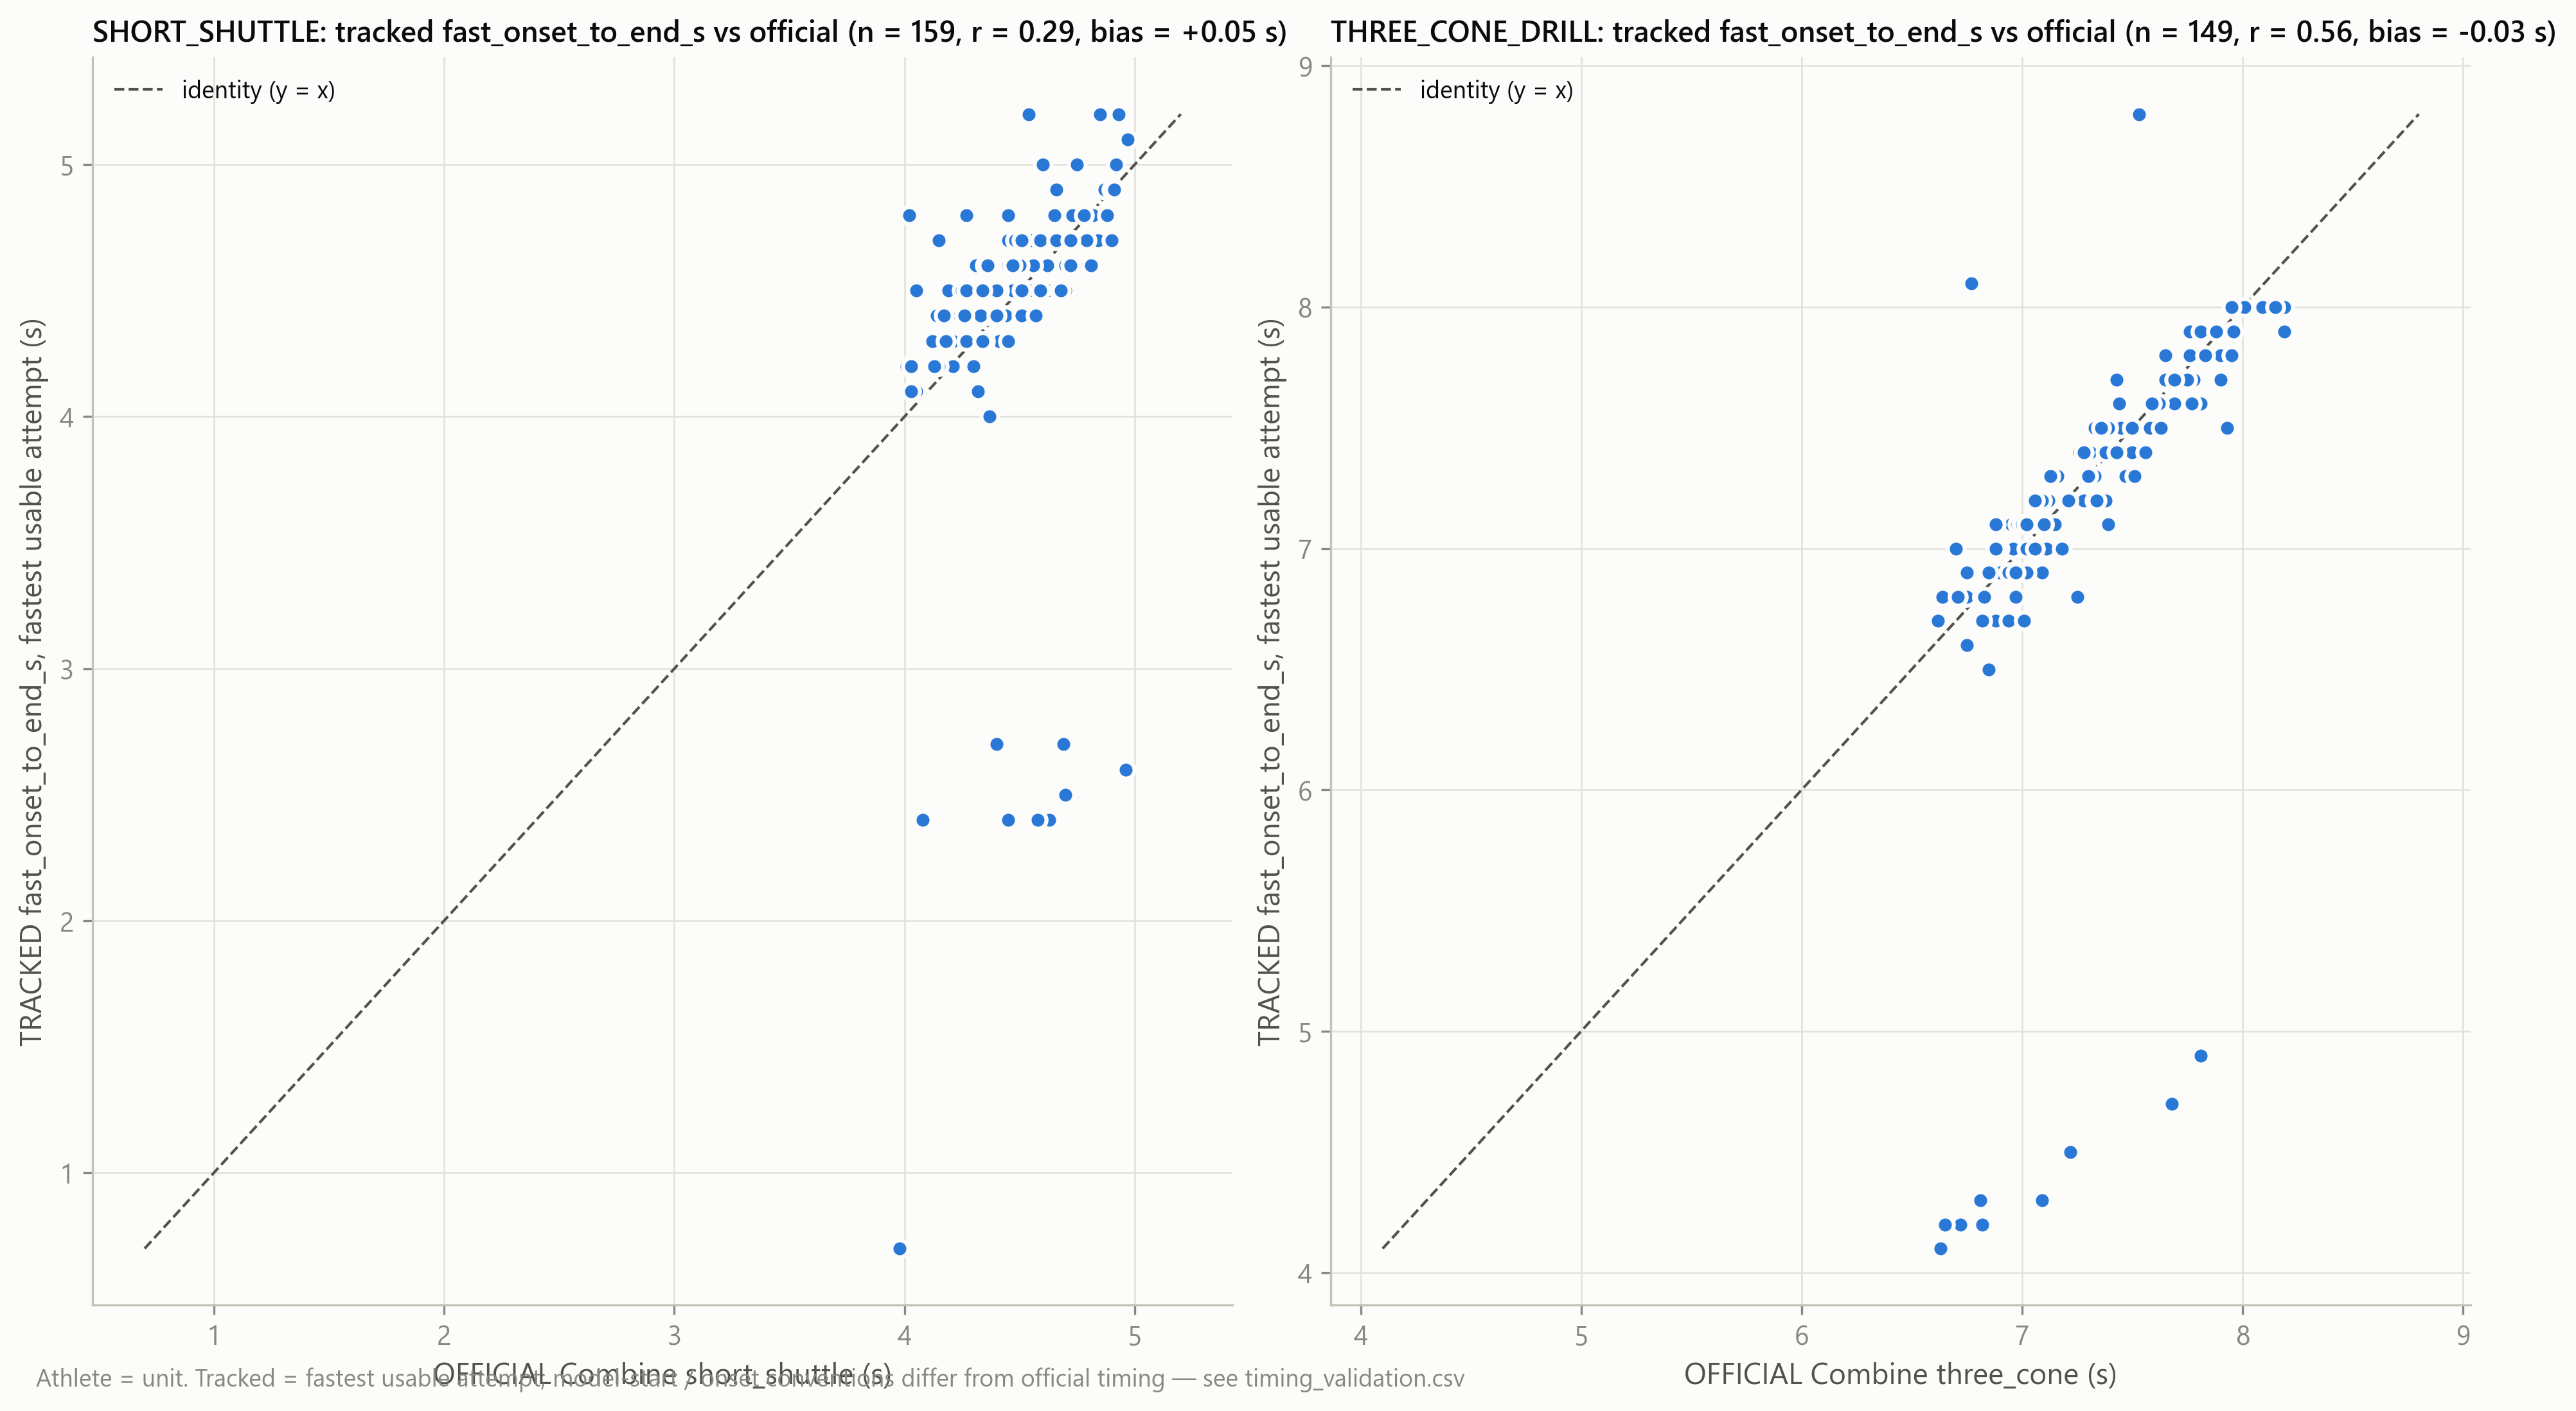

m2_cohort_shift.png


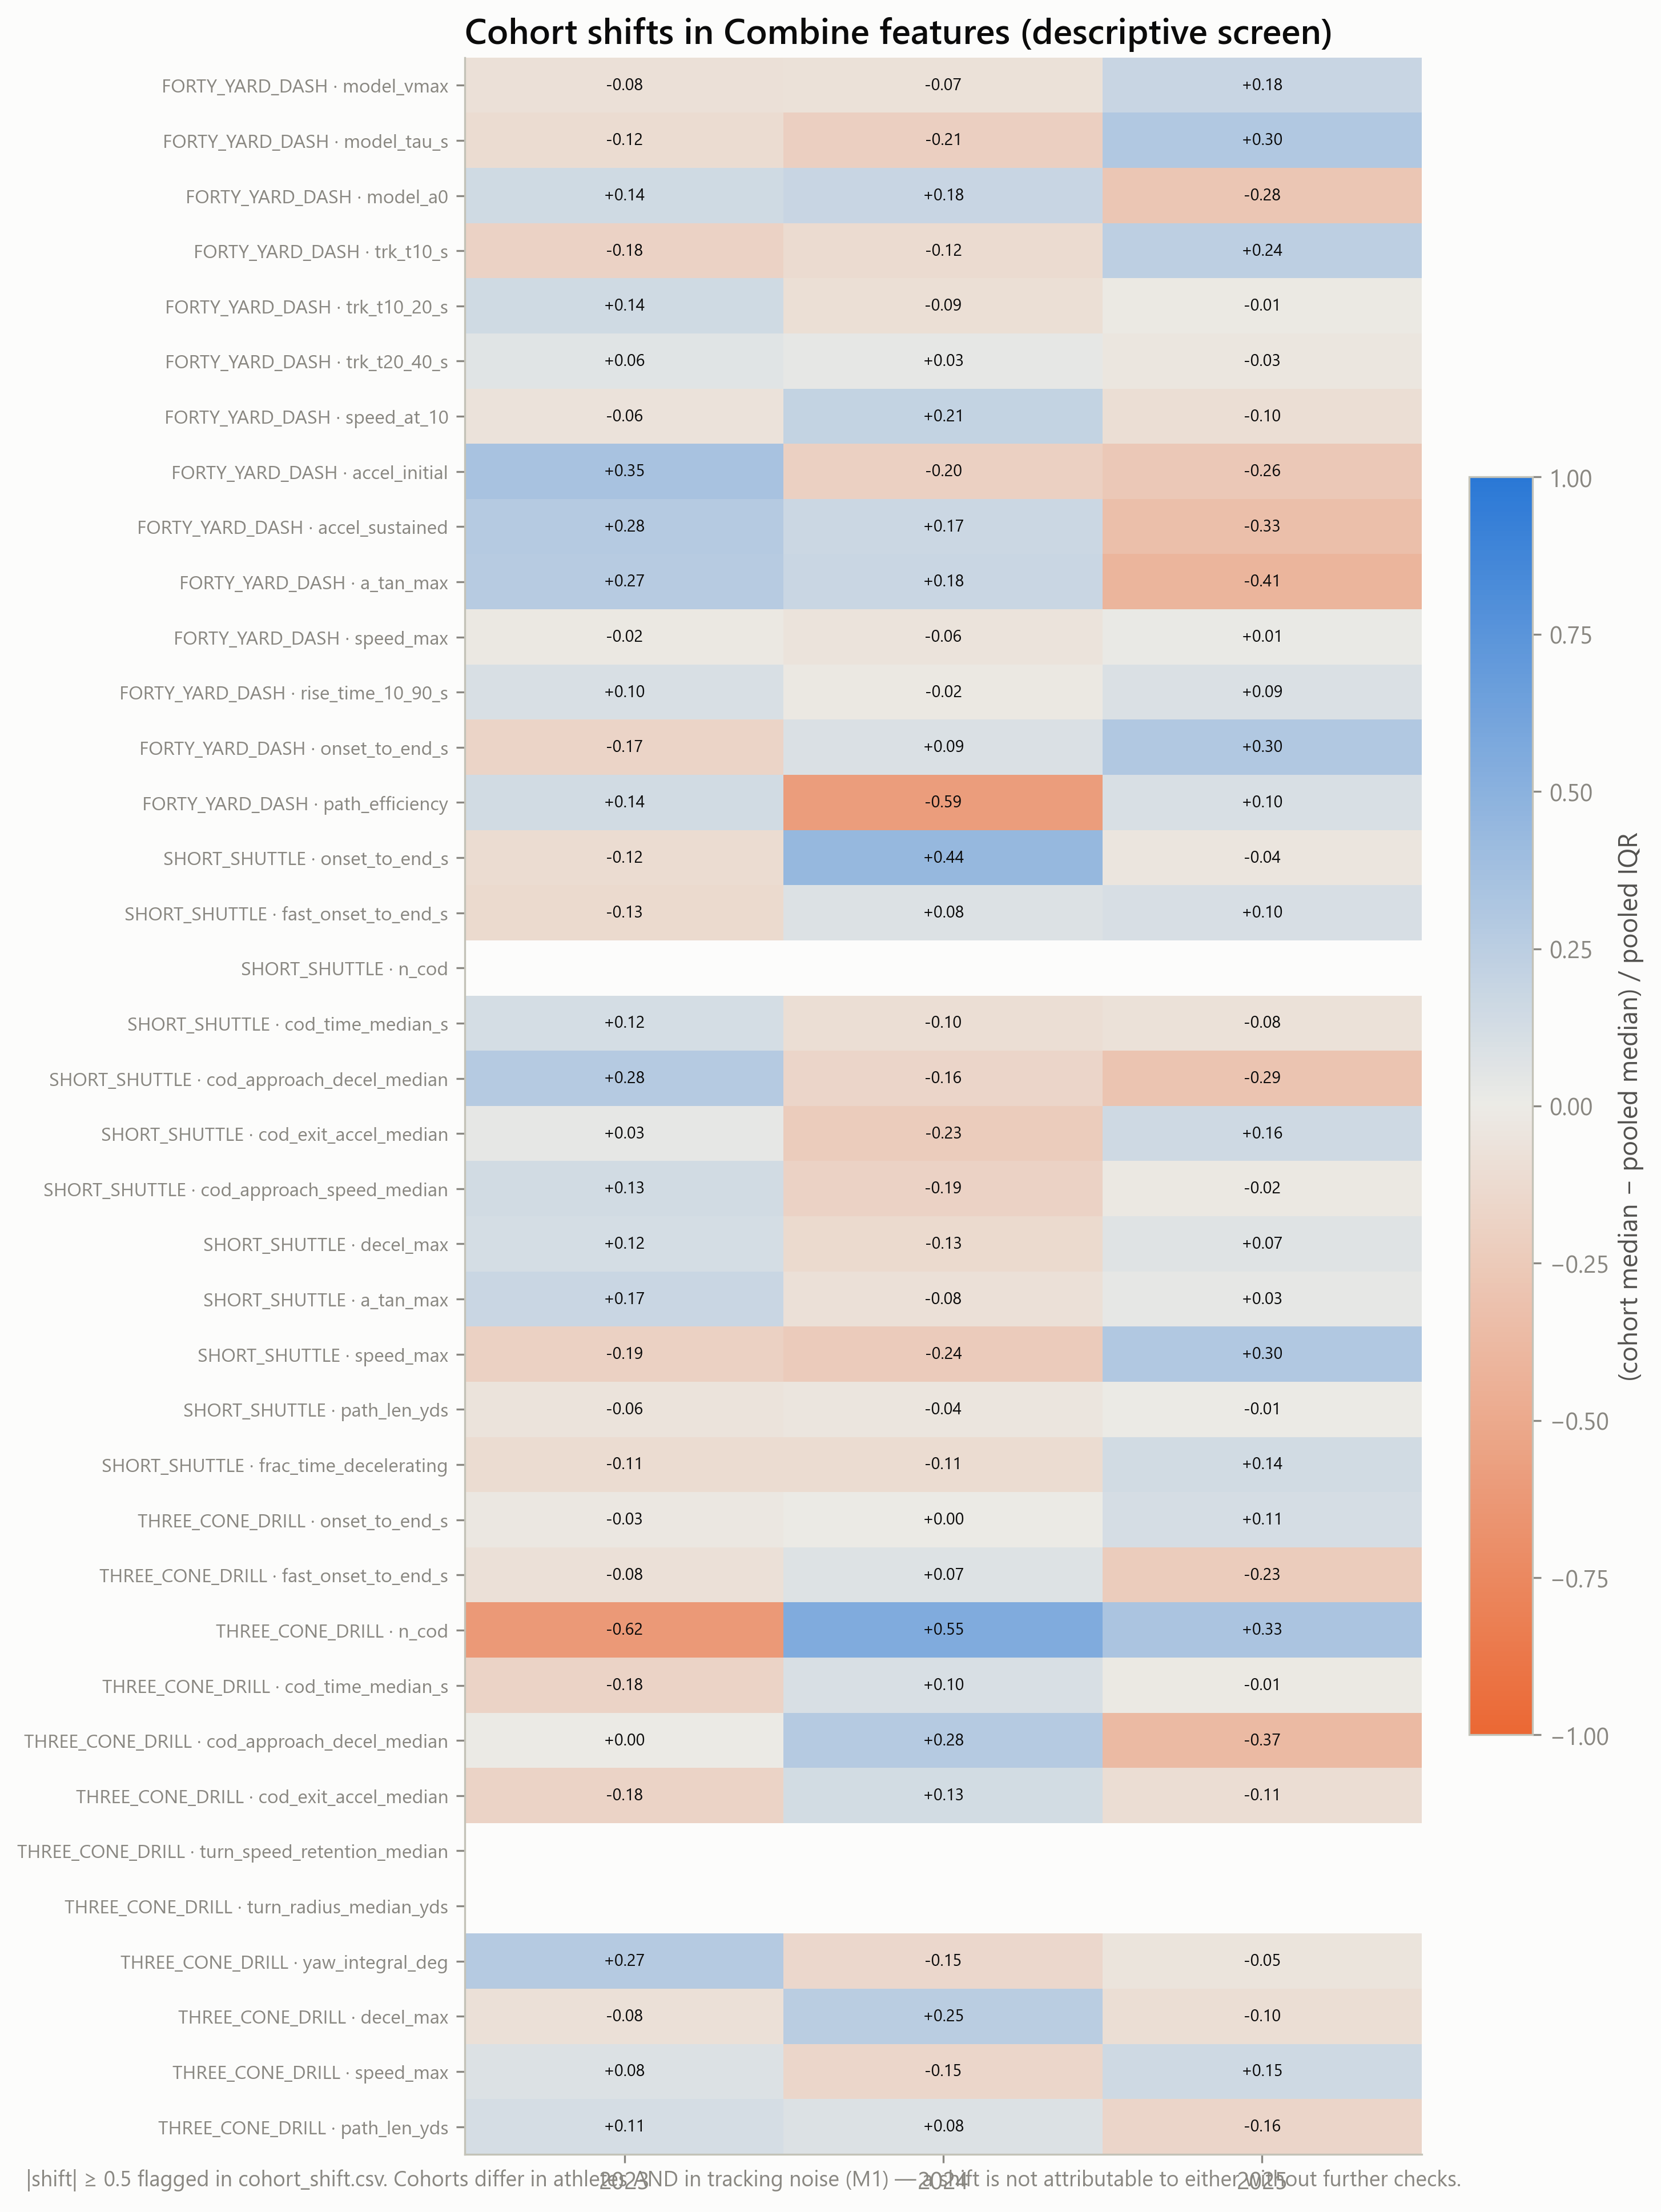

m2_feature_reliability.png


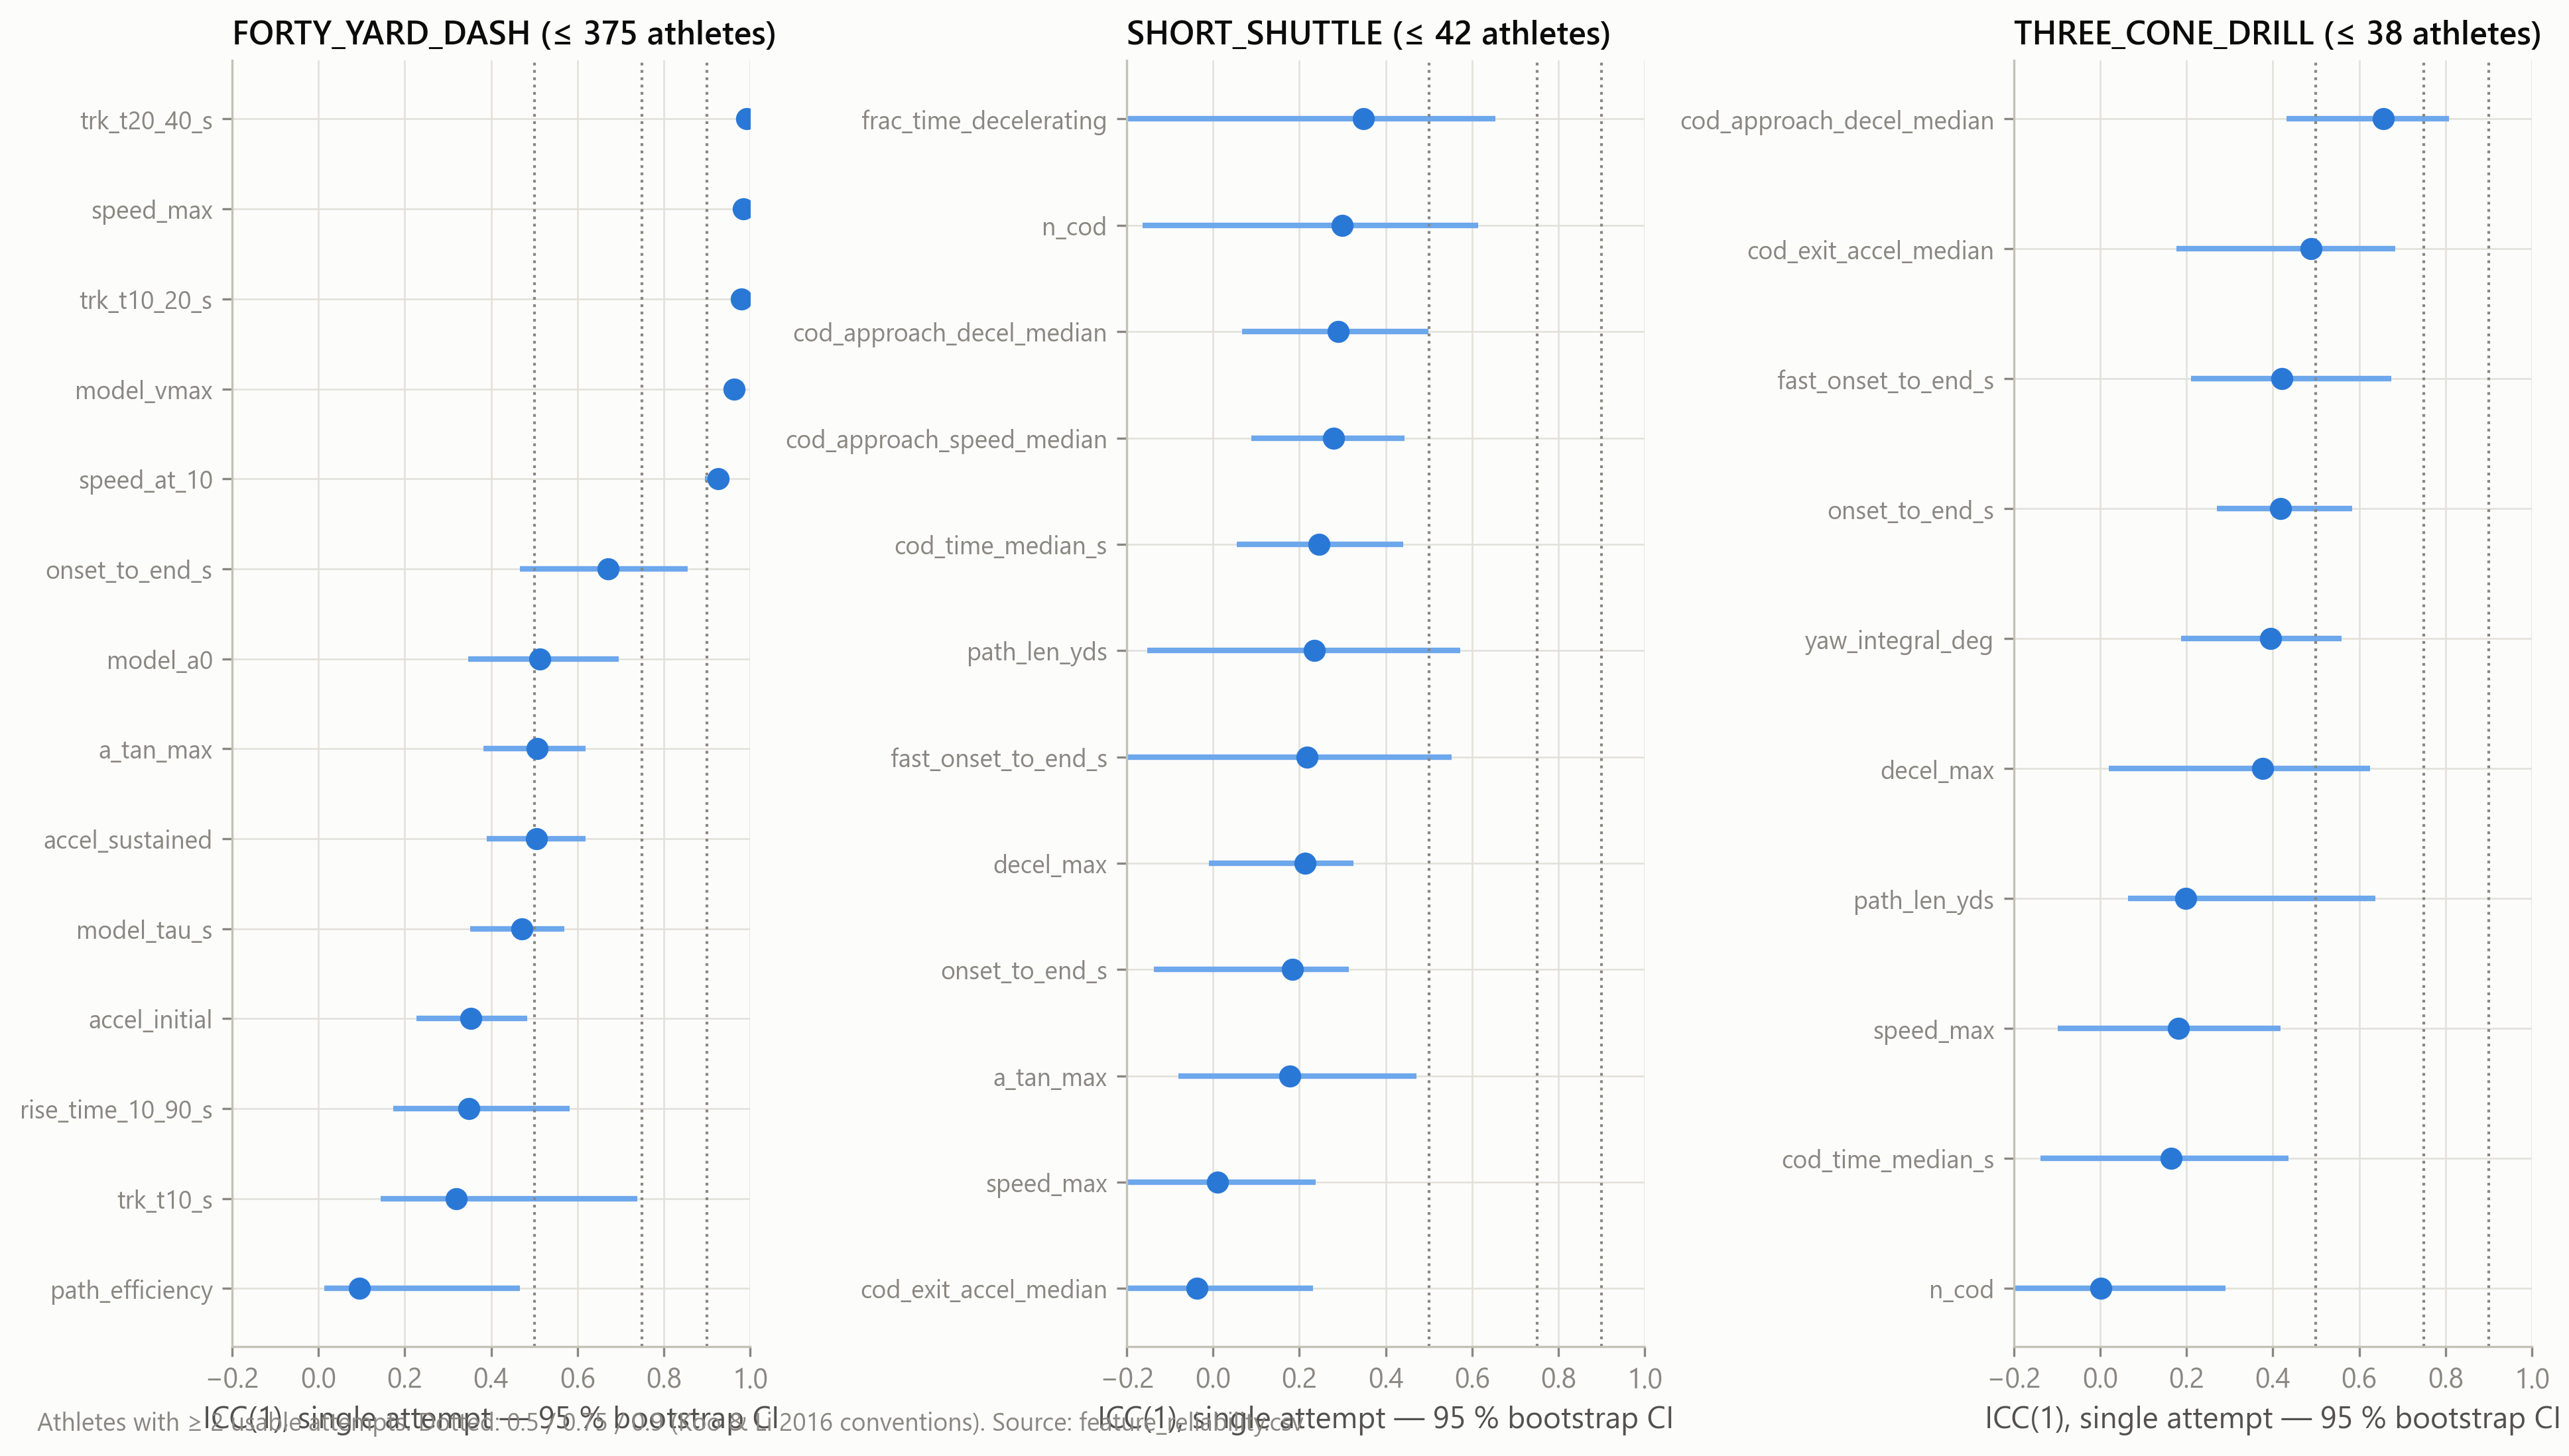

m2_forty_acceleration_extremes.png


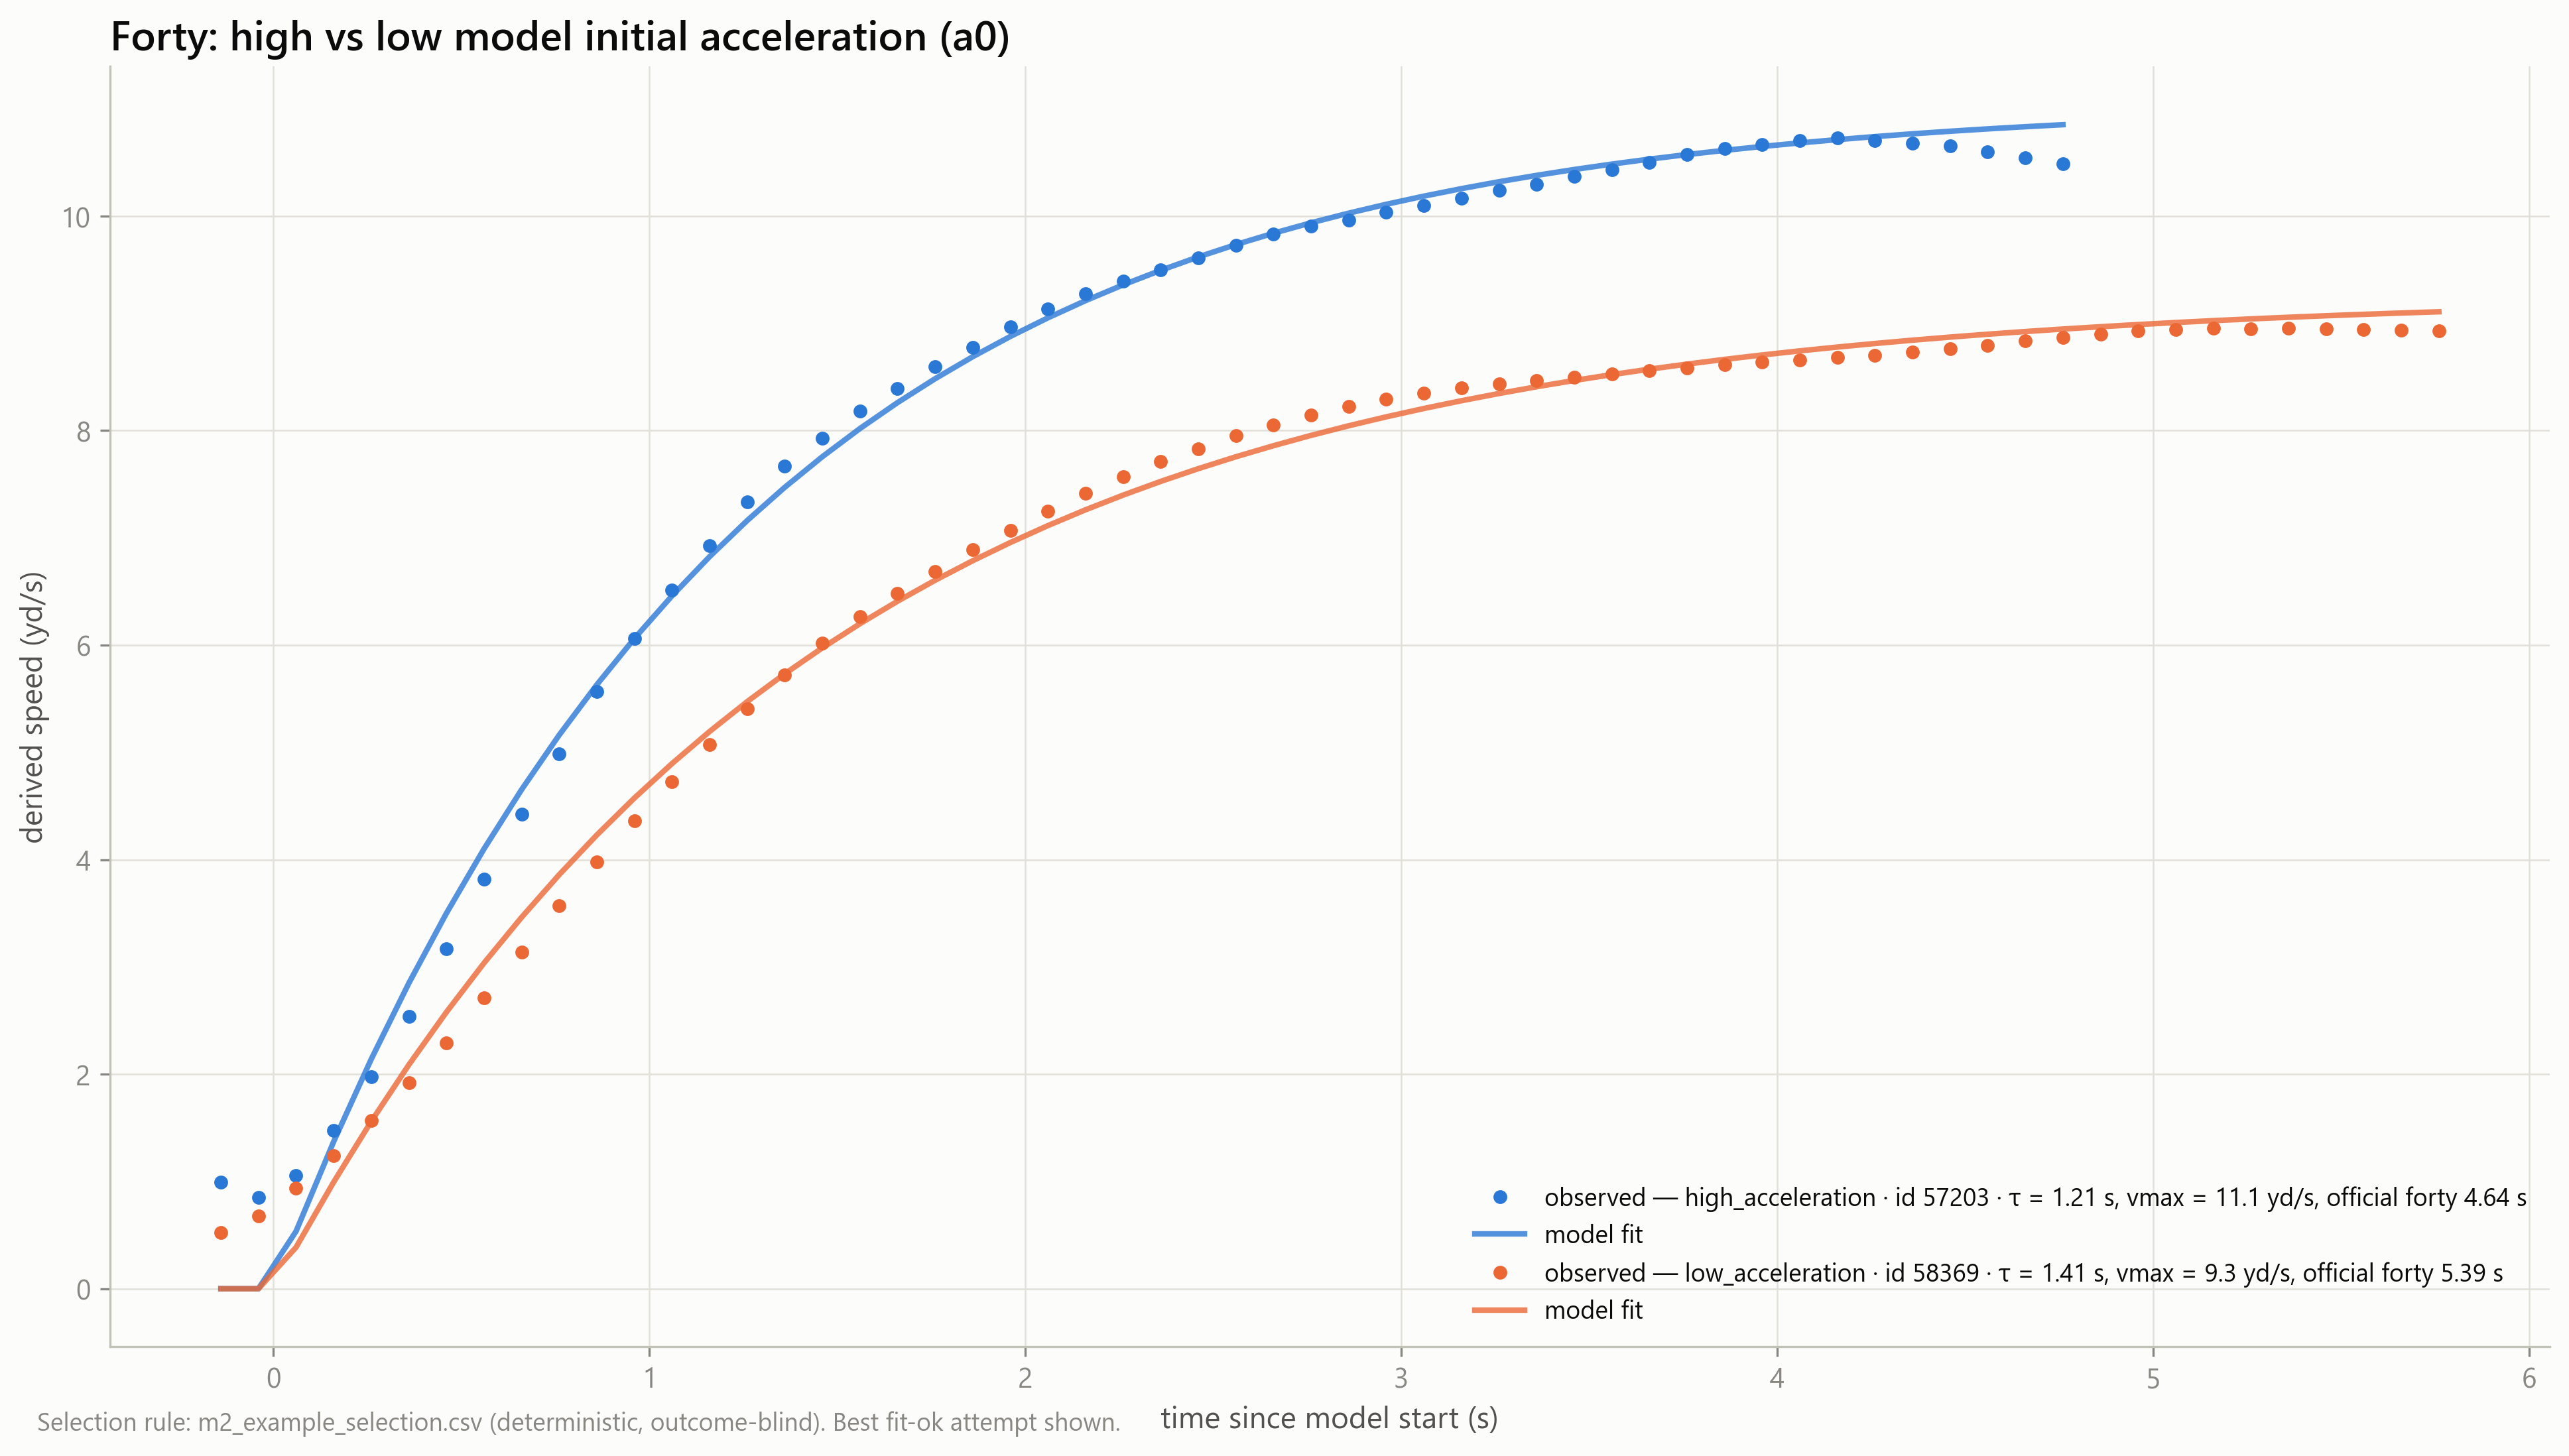

m2_forty_attempt_stability.png


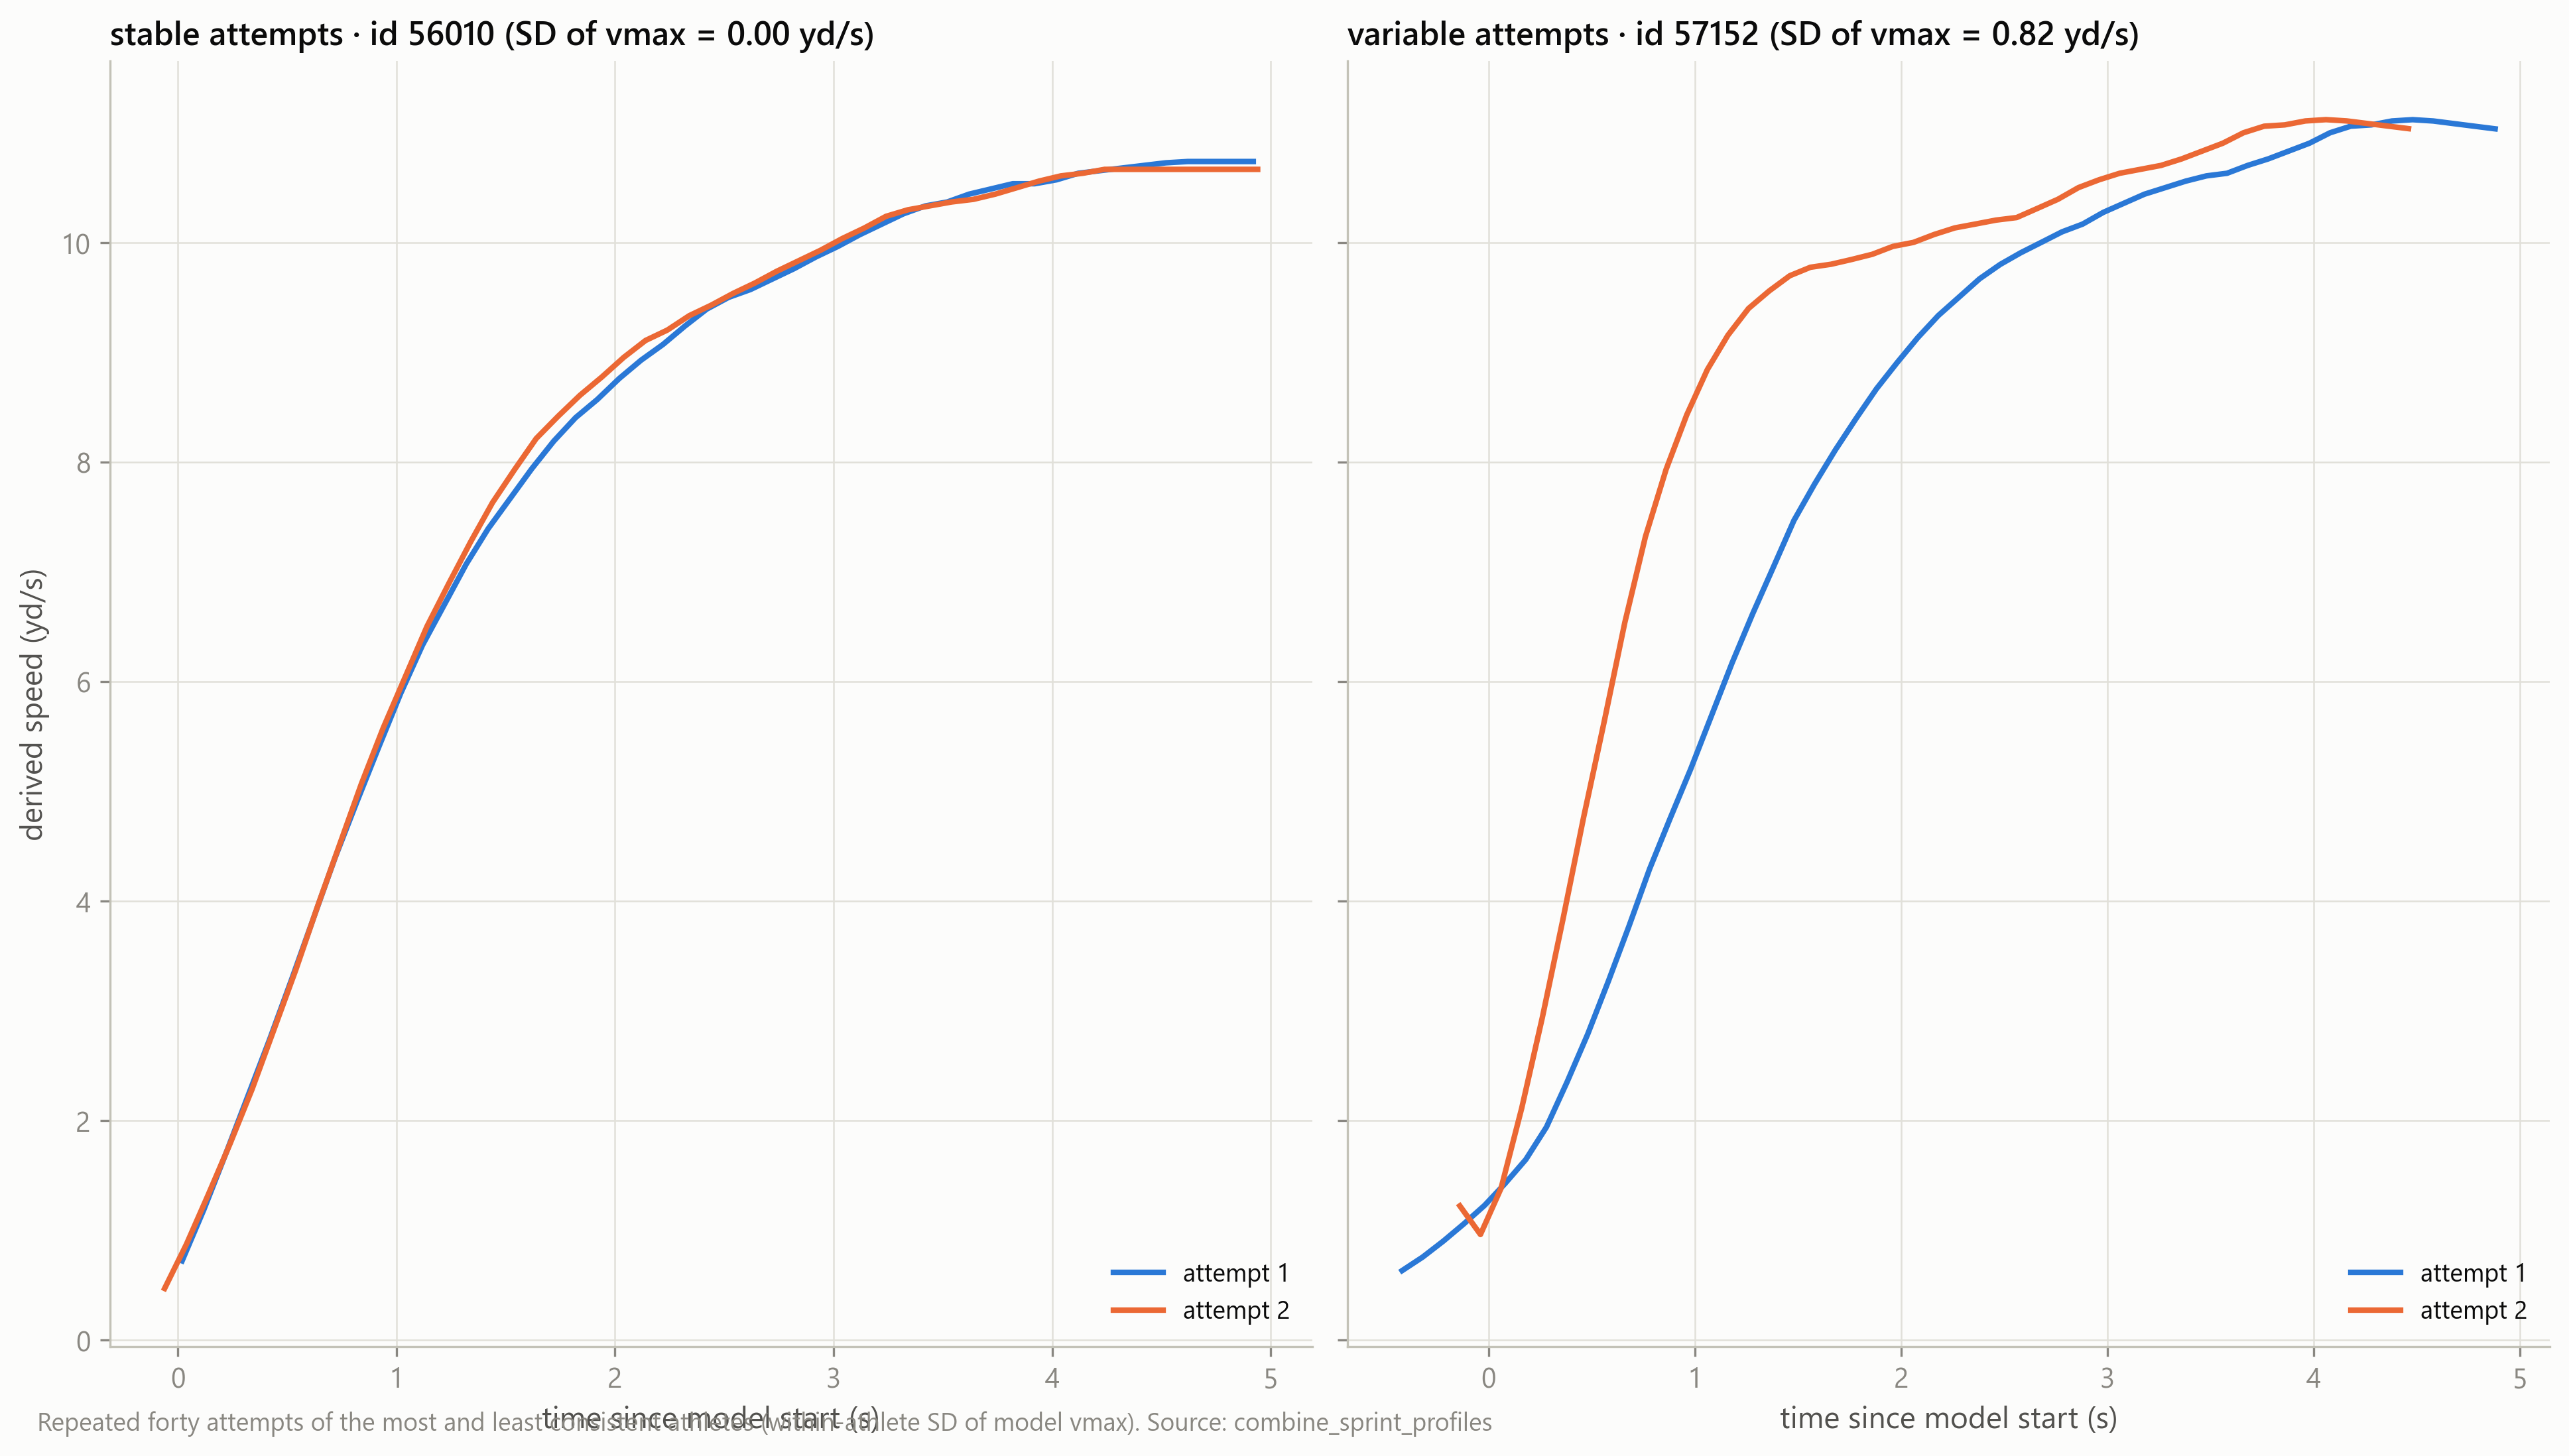

m2_forty_feature_correlation.png


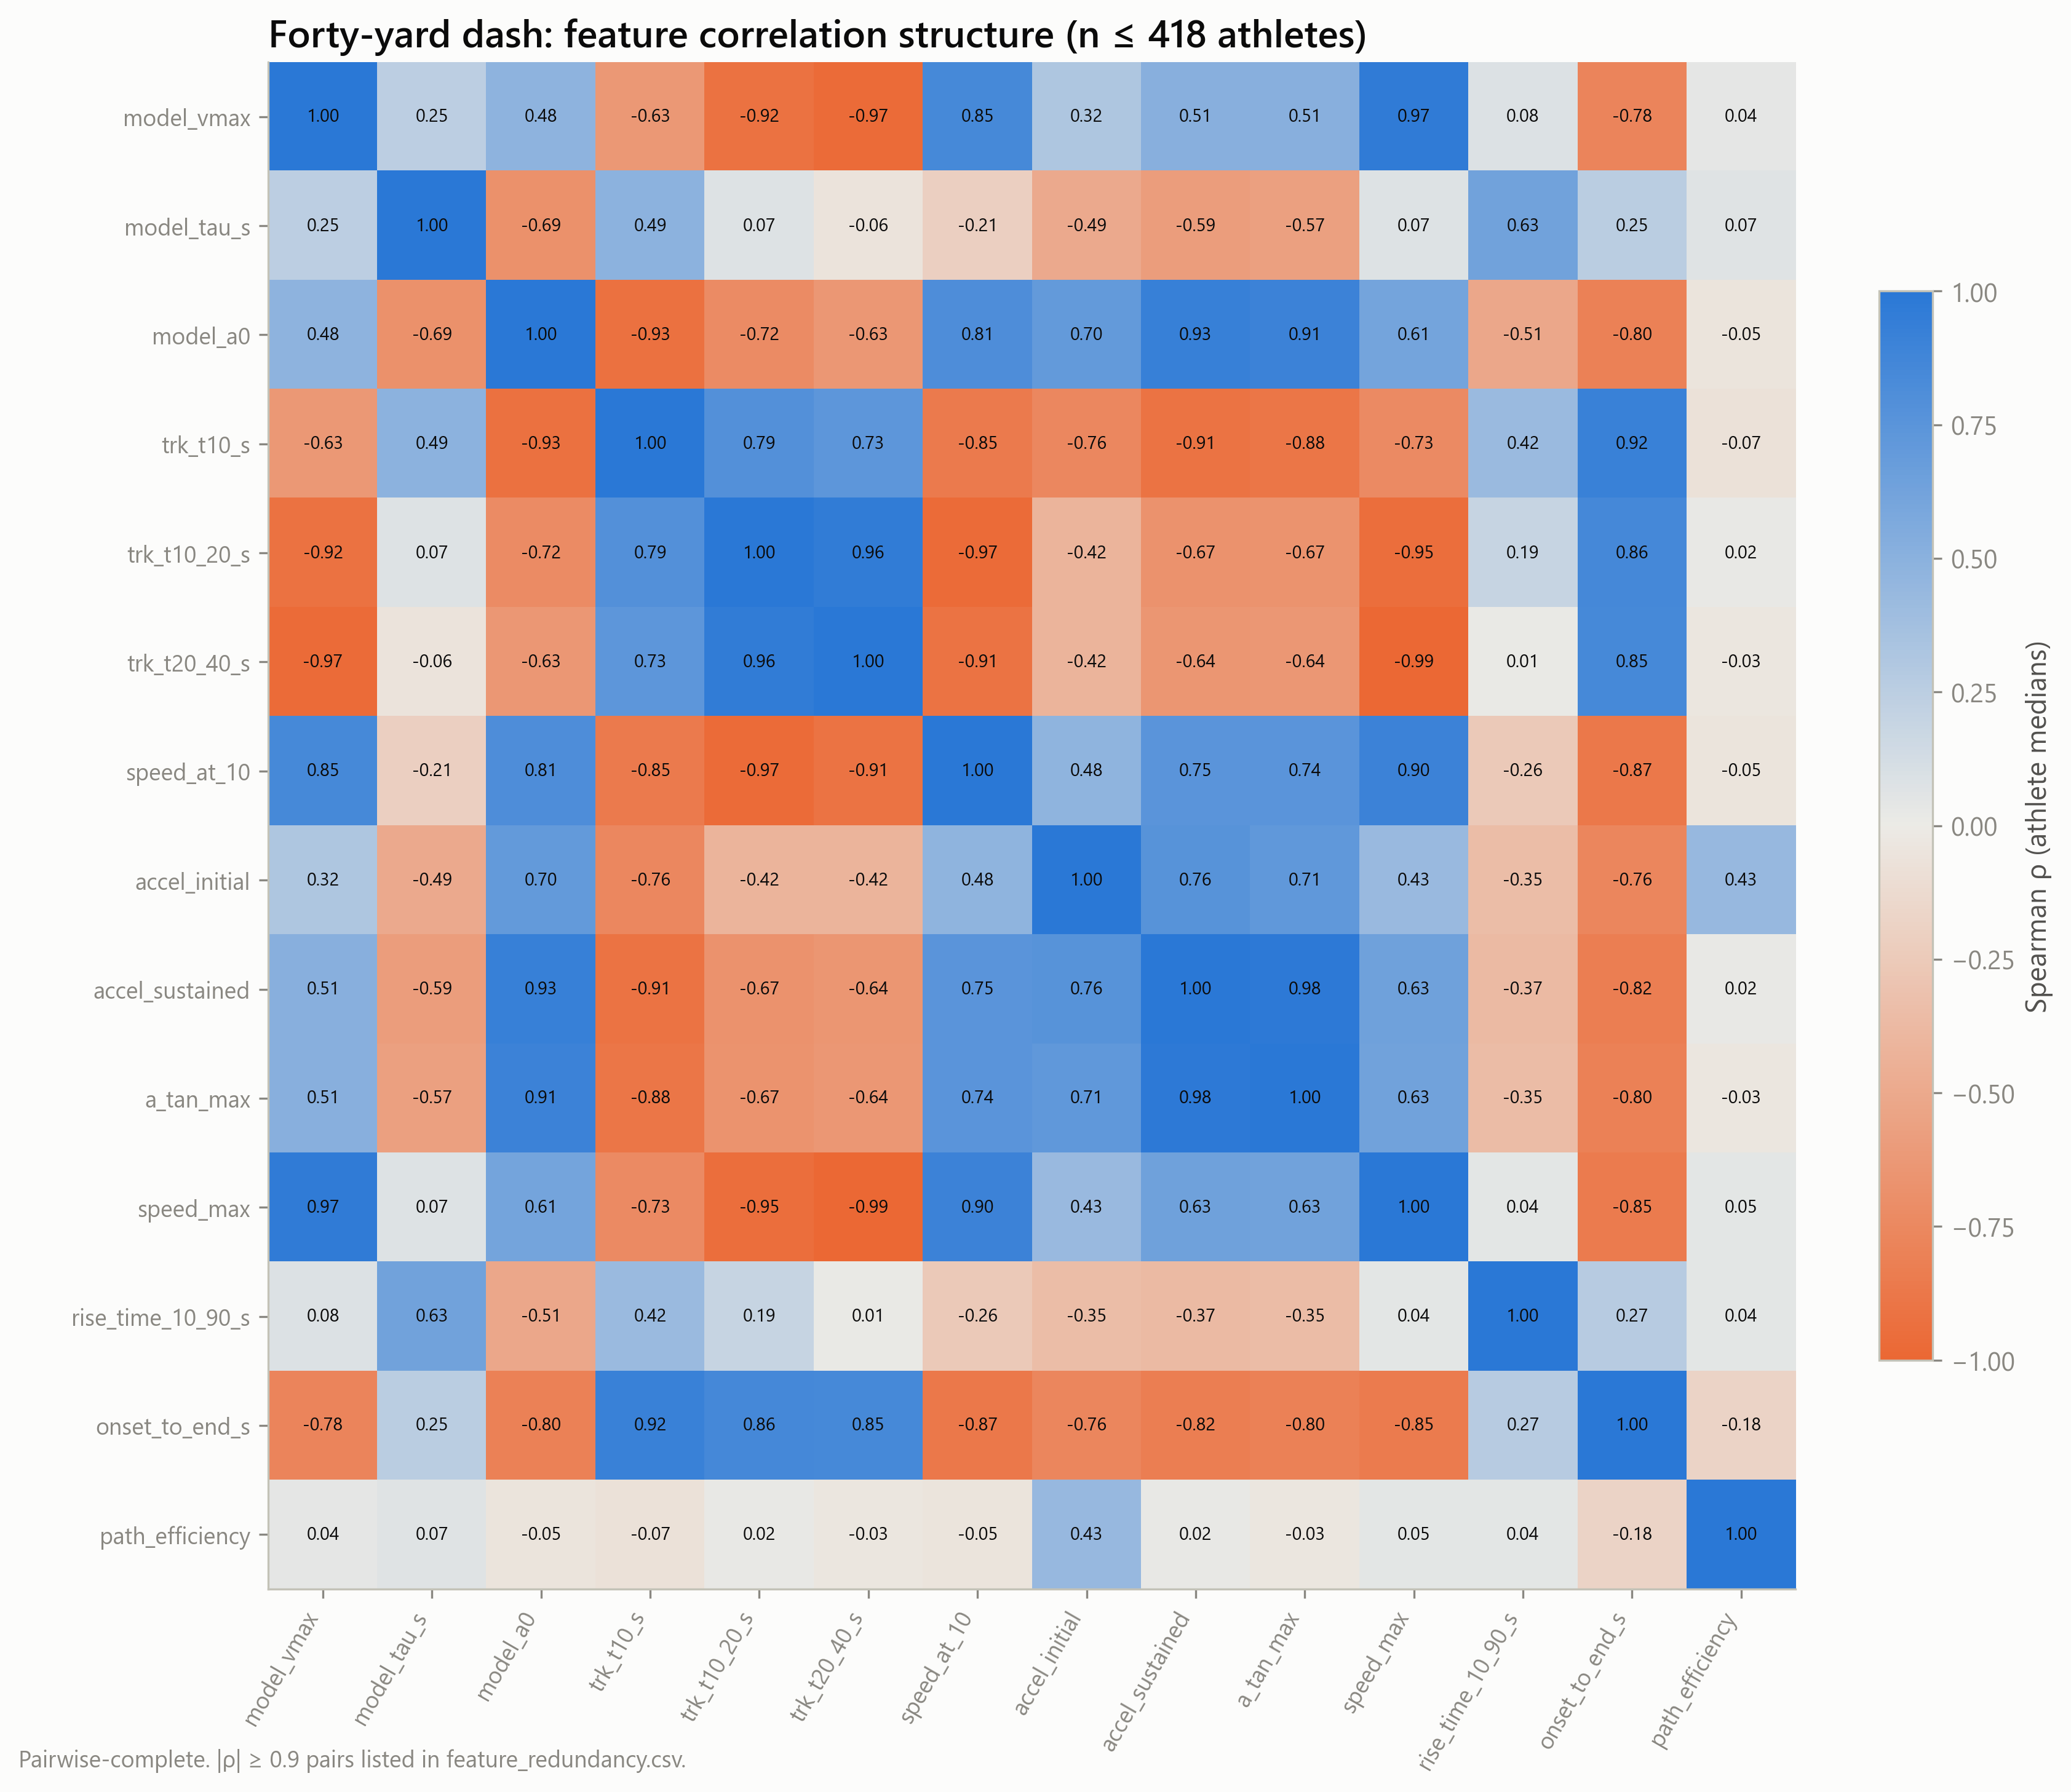

m2_forty_similar_time_different_profile.png


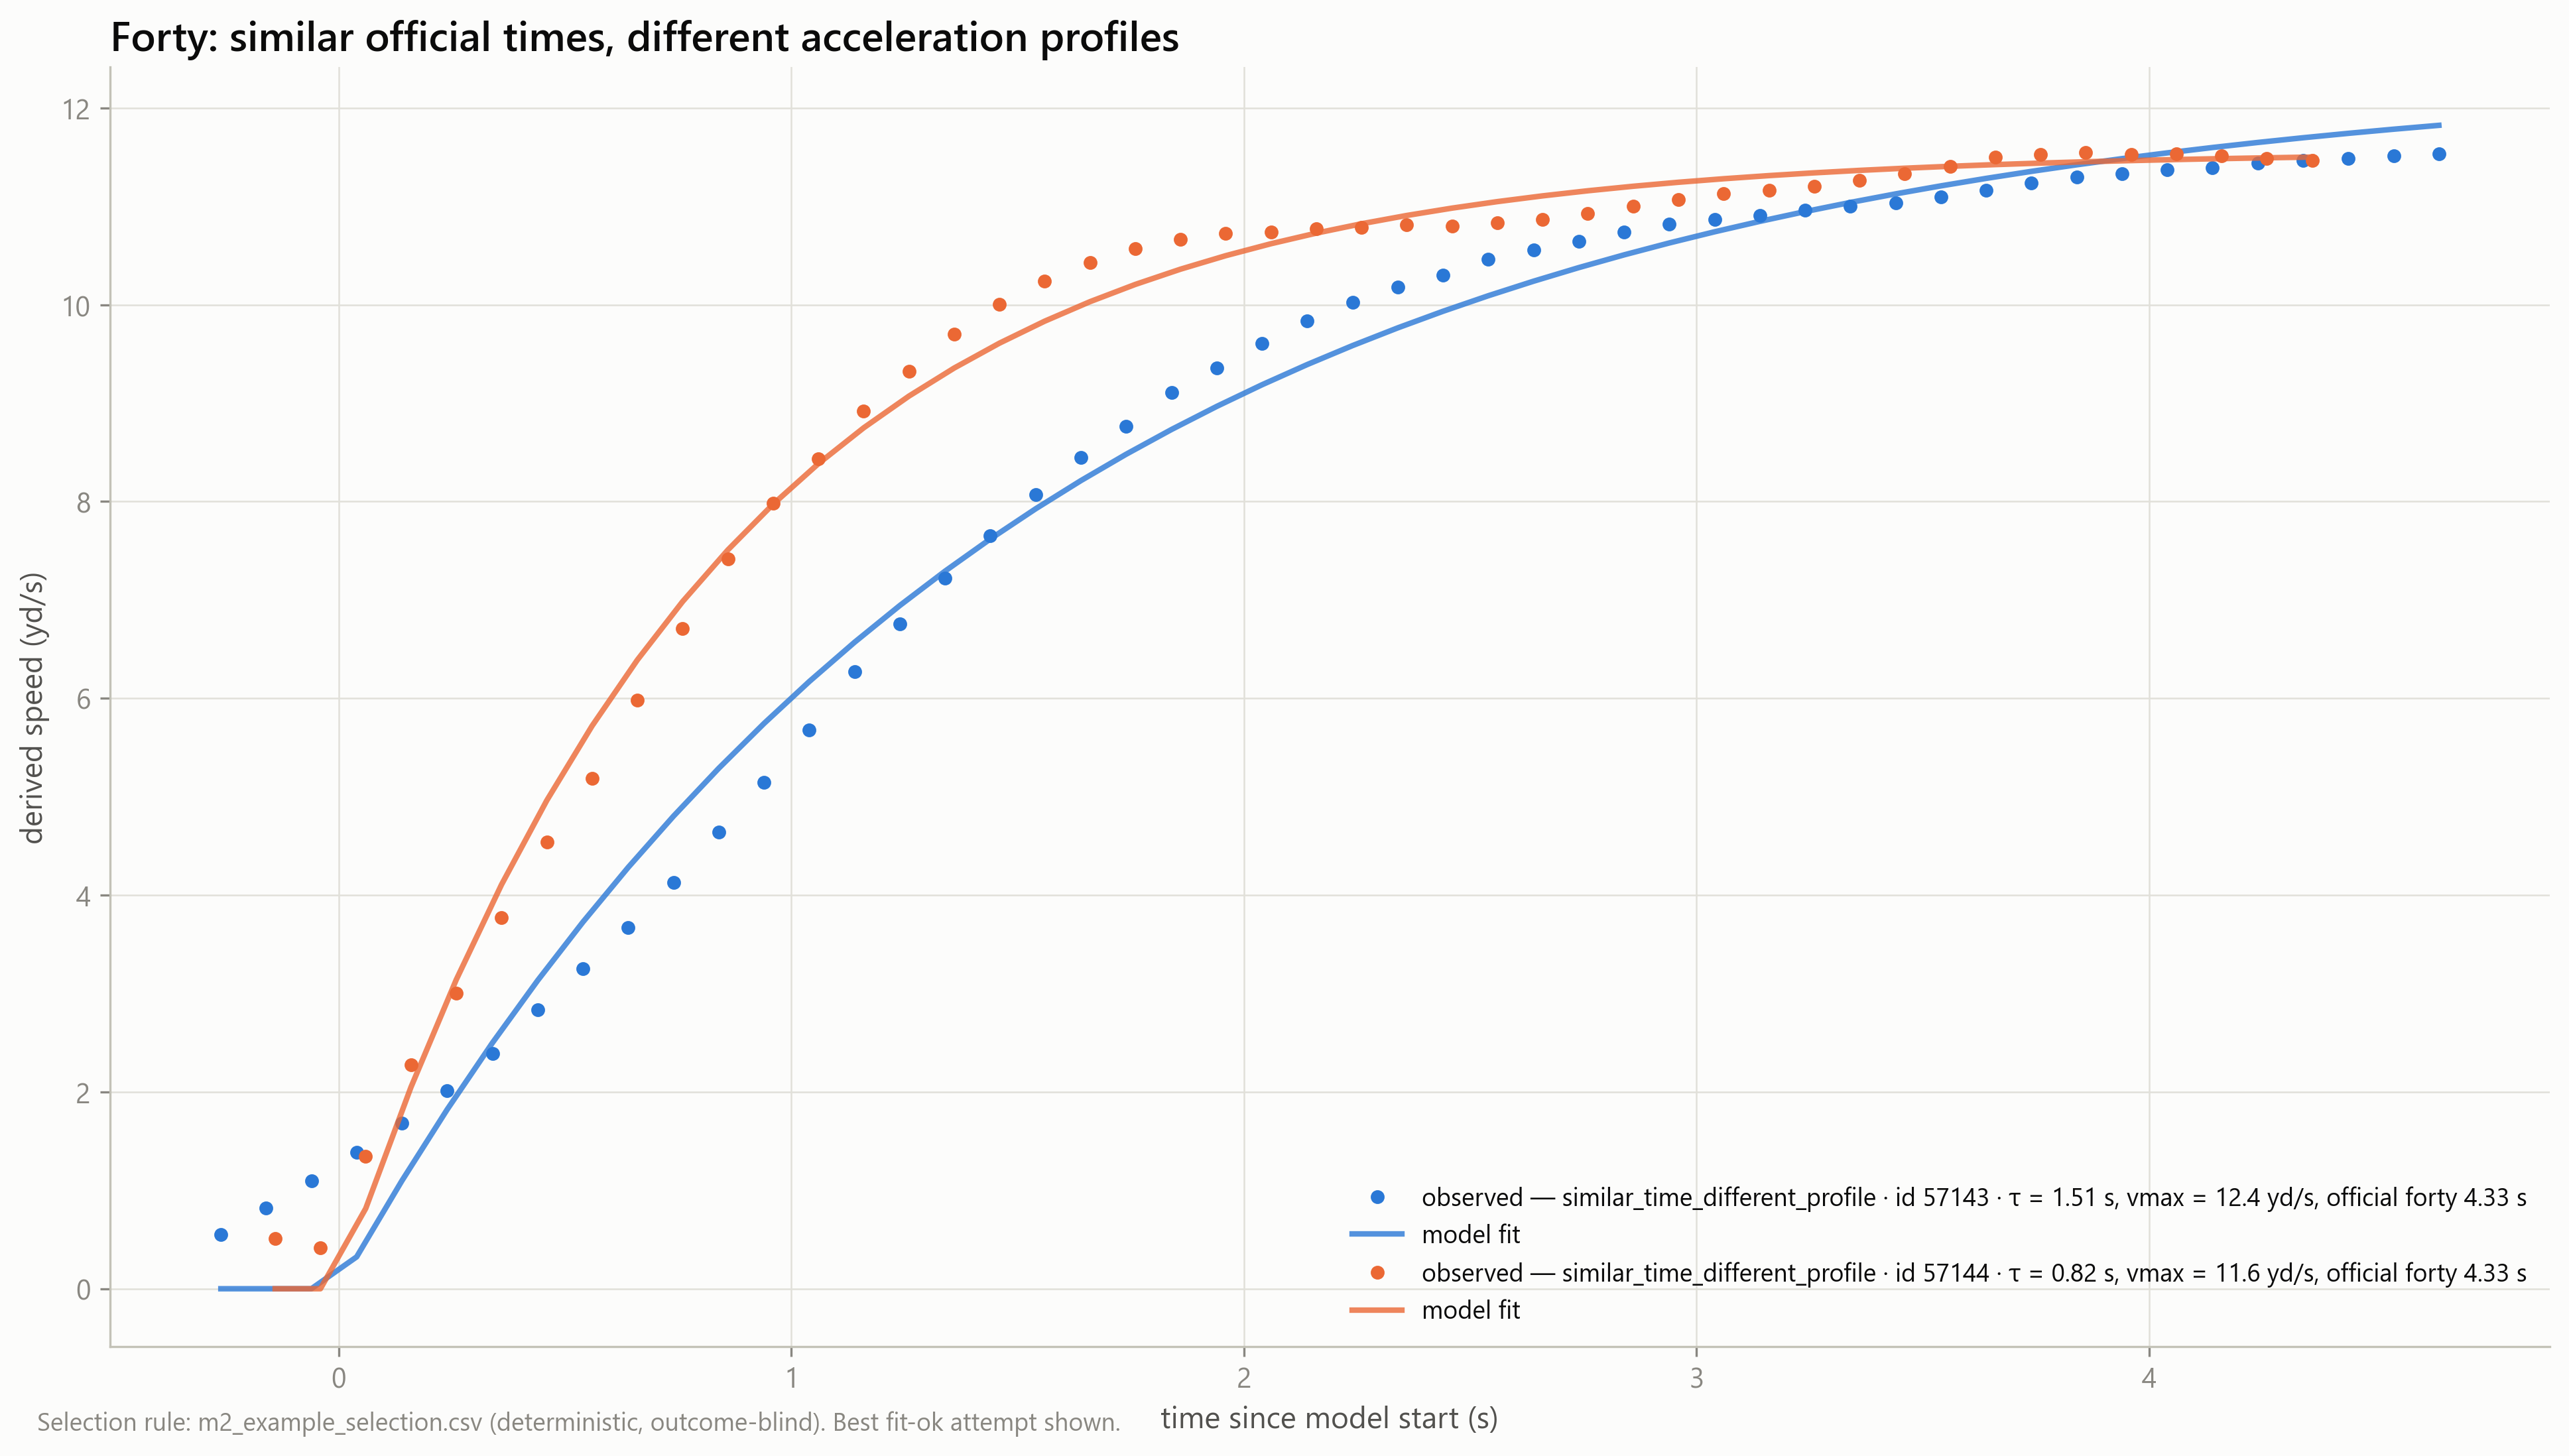

m2_forty_speed_profiles_by_position.png


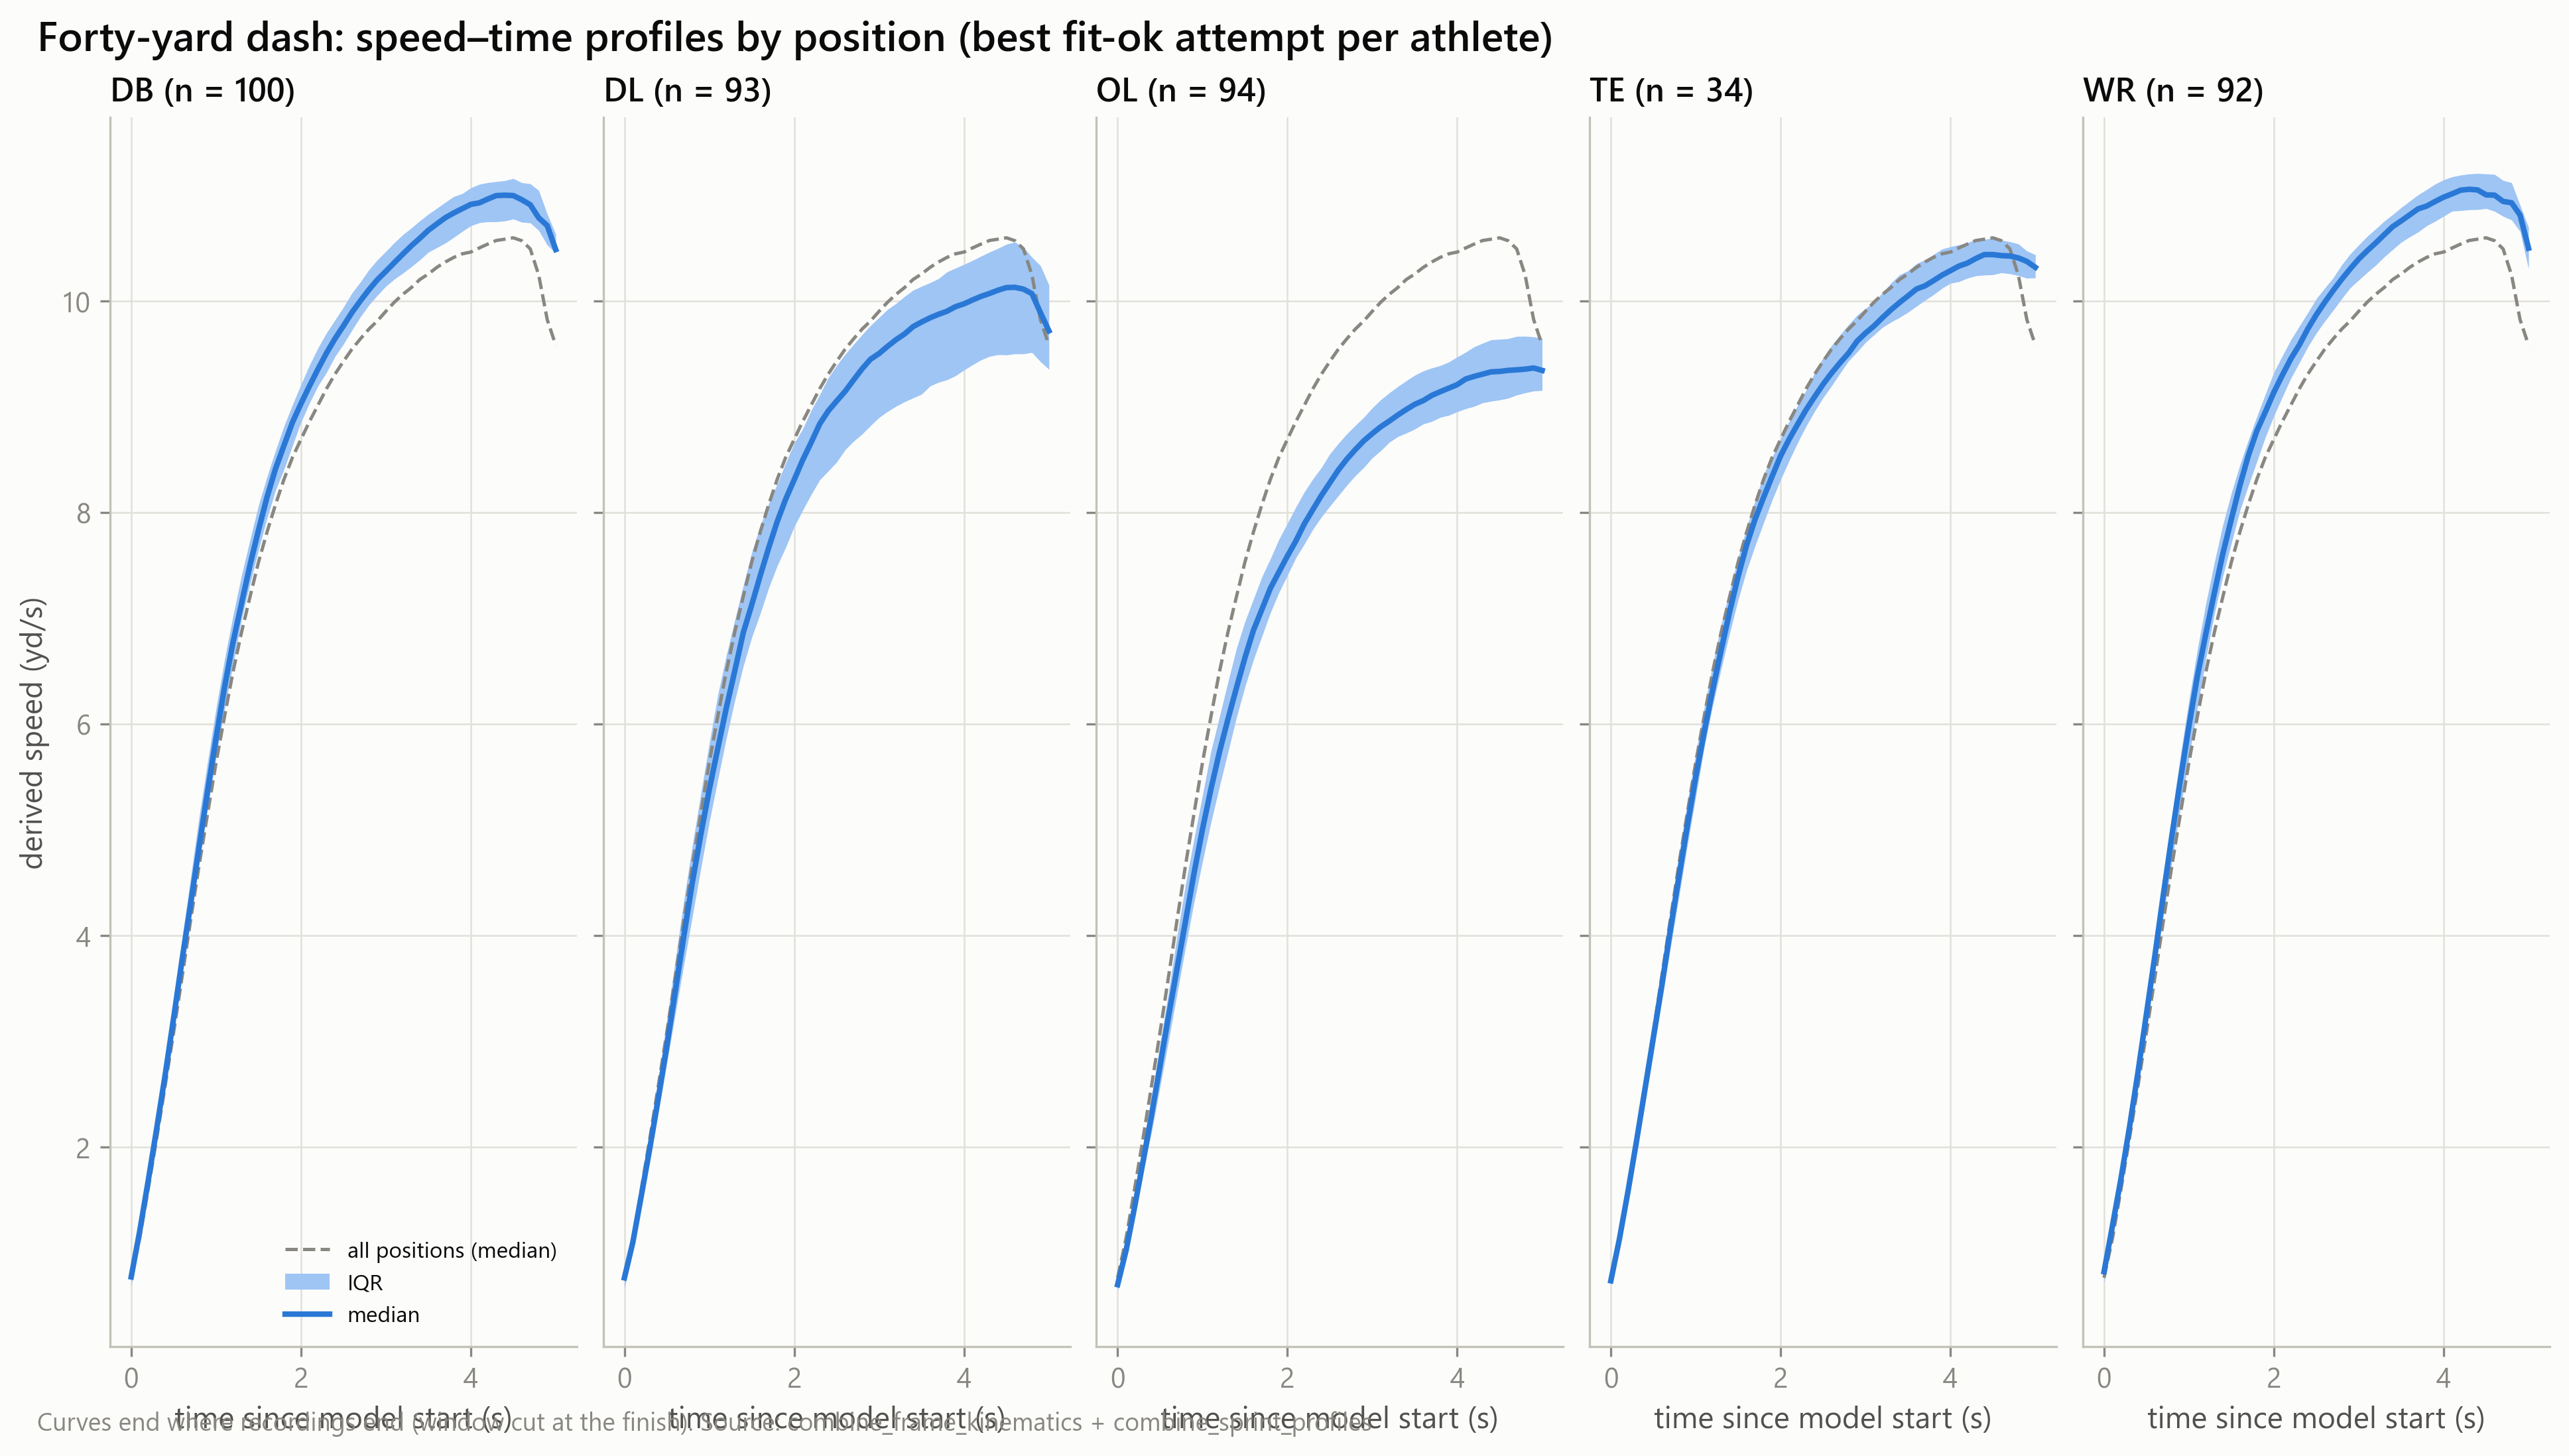

m2_forty_timing_validation.png


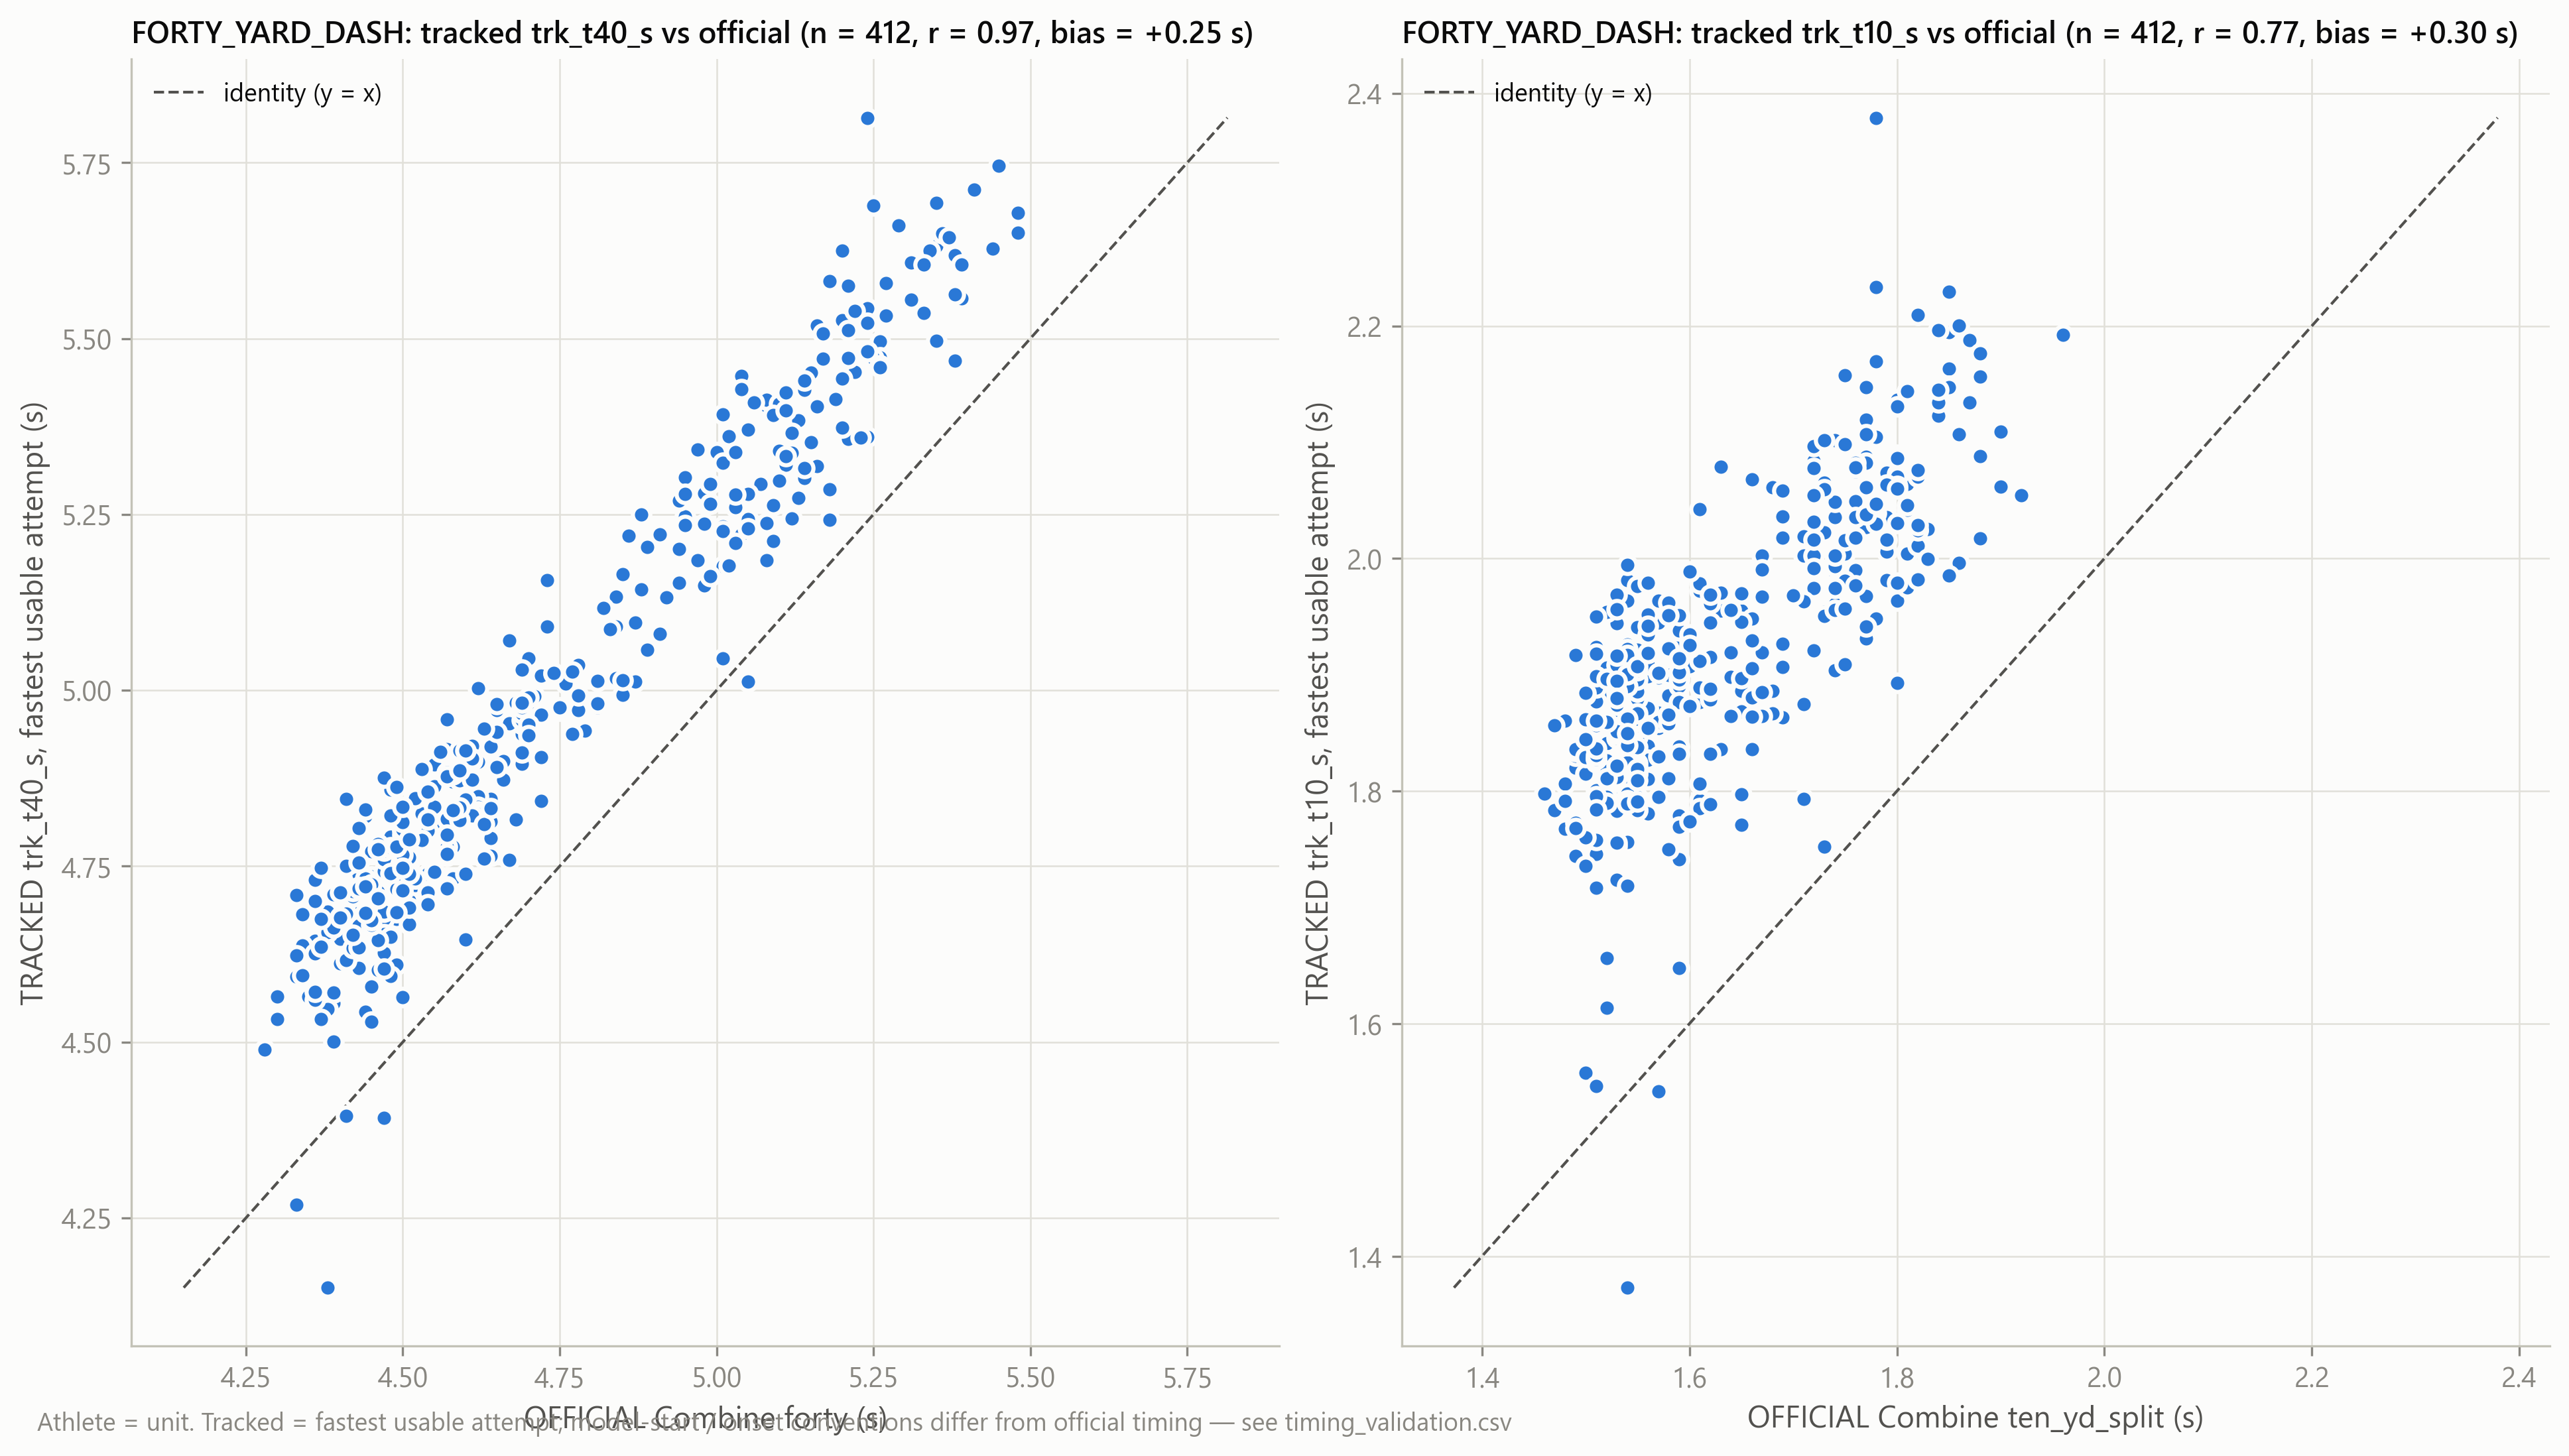

m2_position_distributions.png


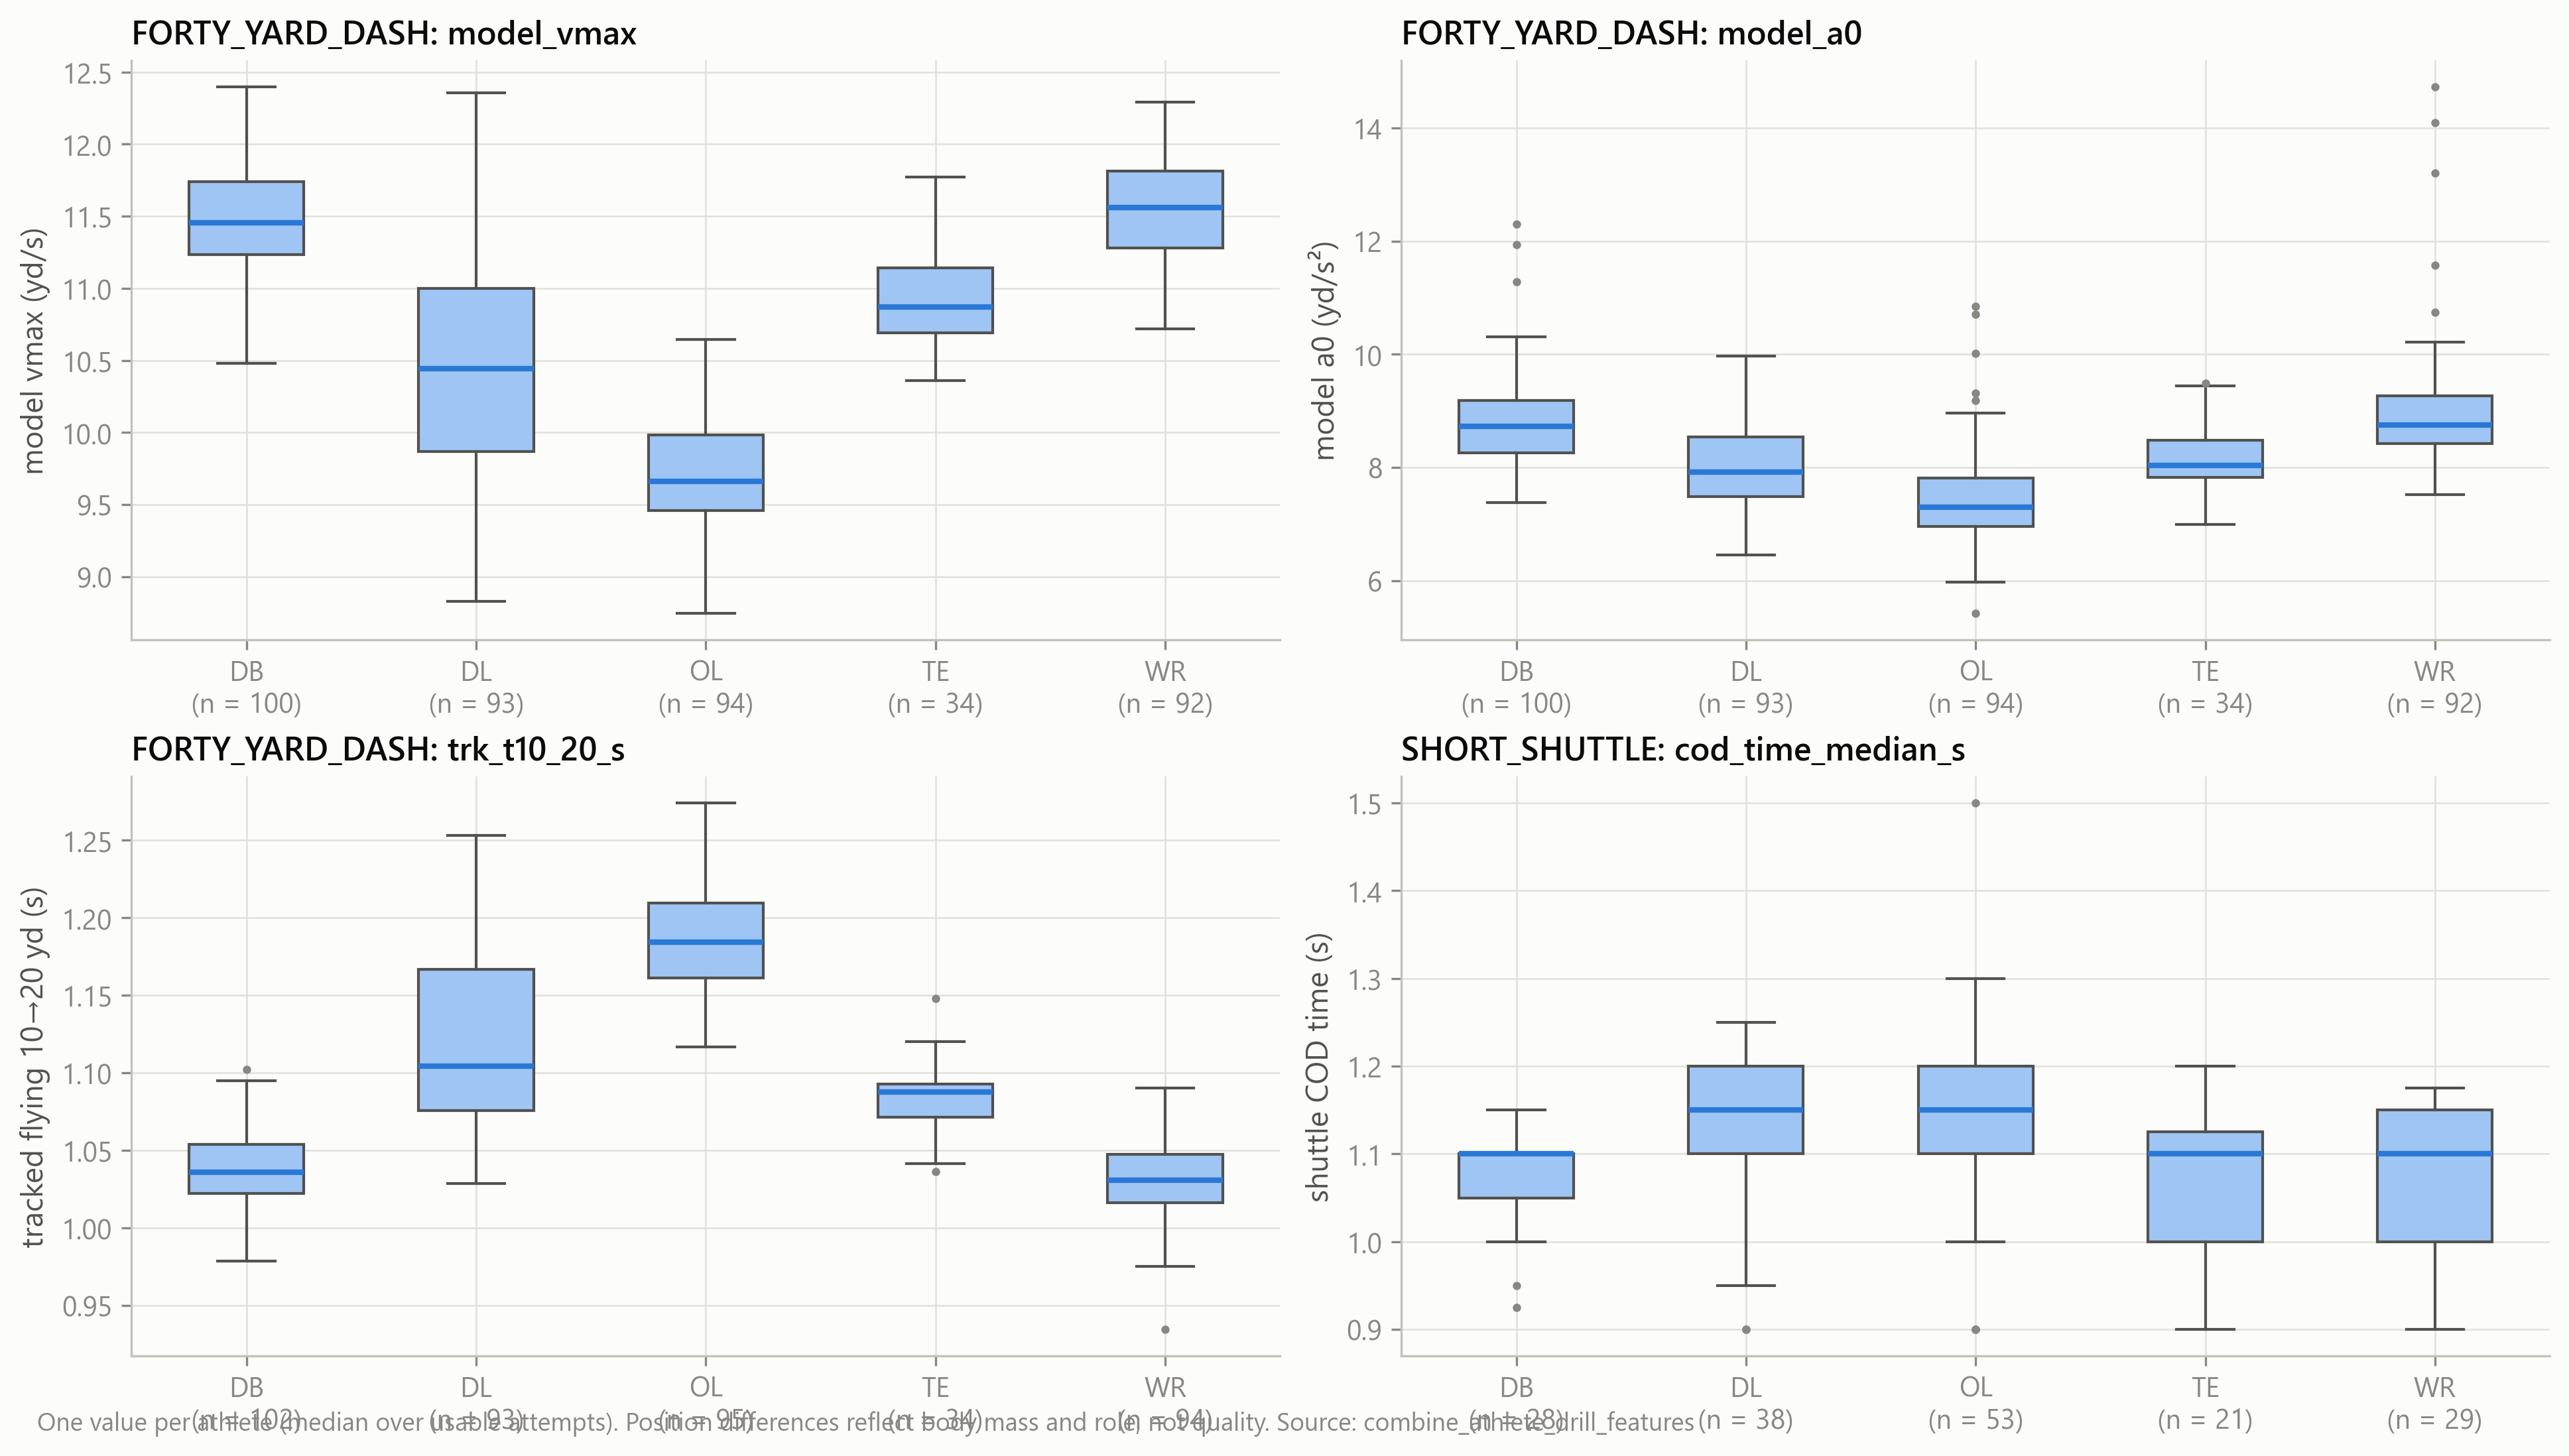

m2_shuttle_braking_extremes.png


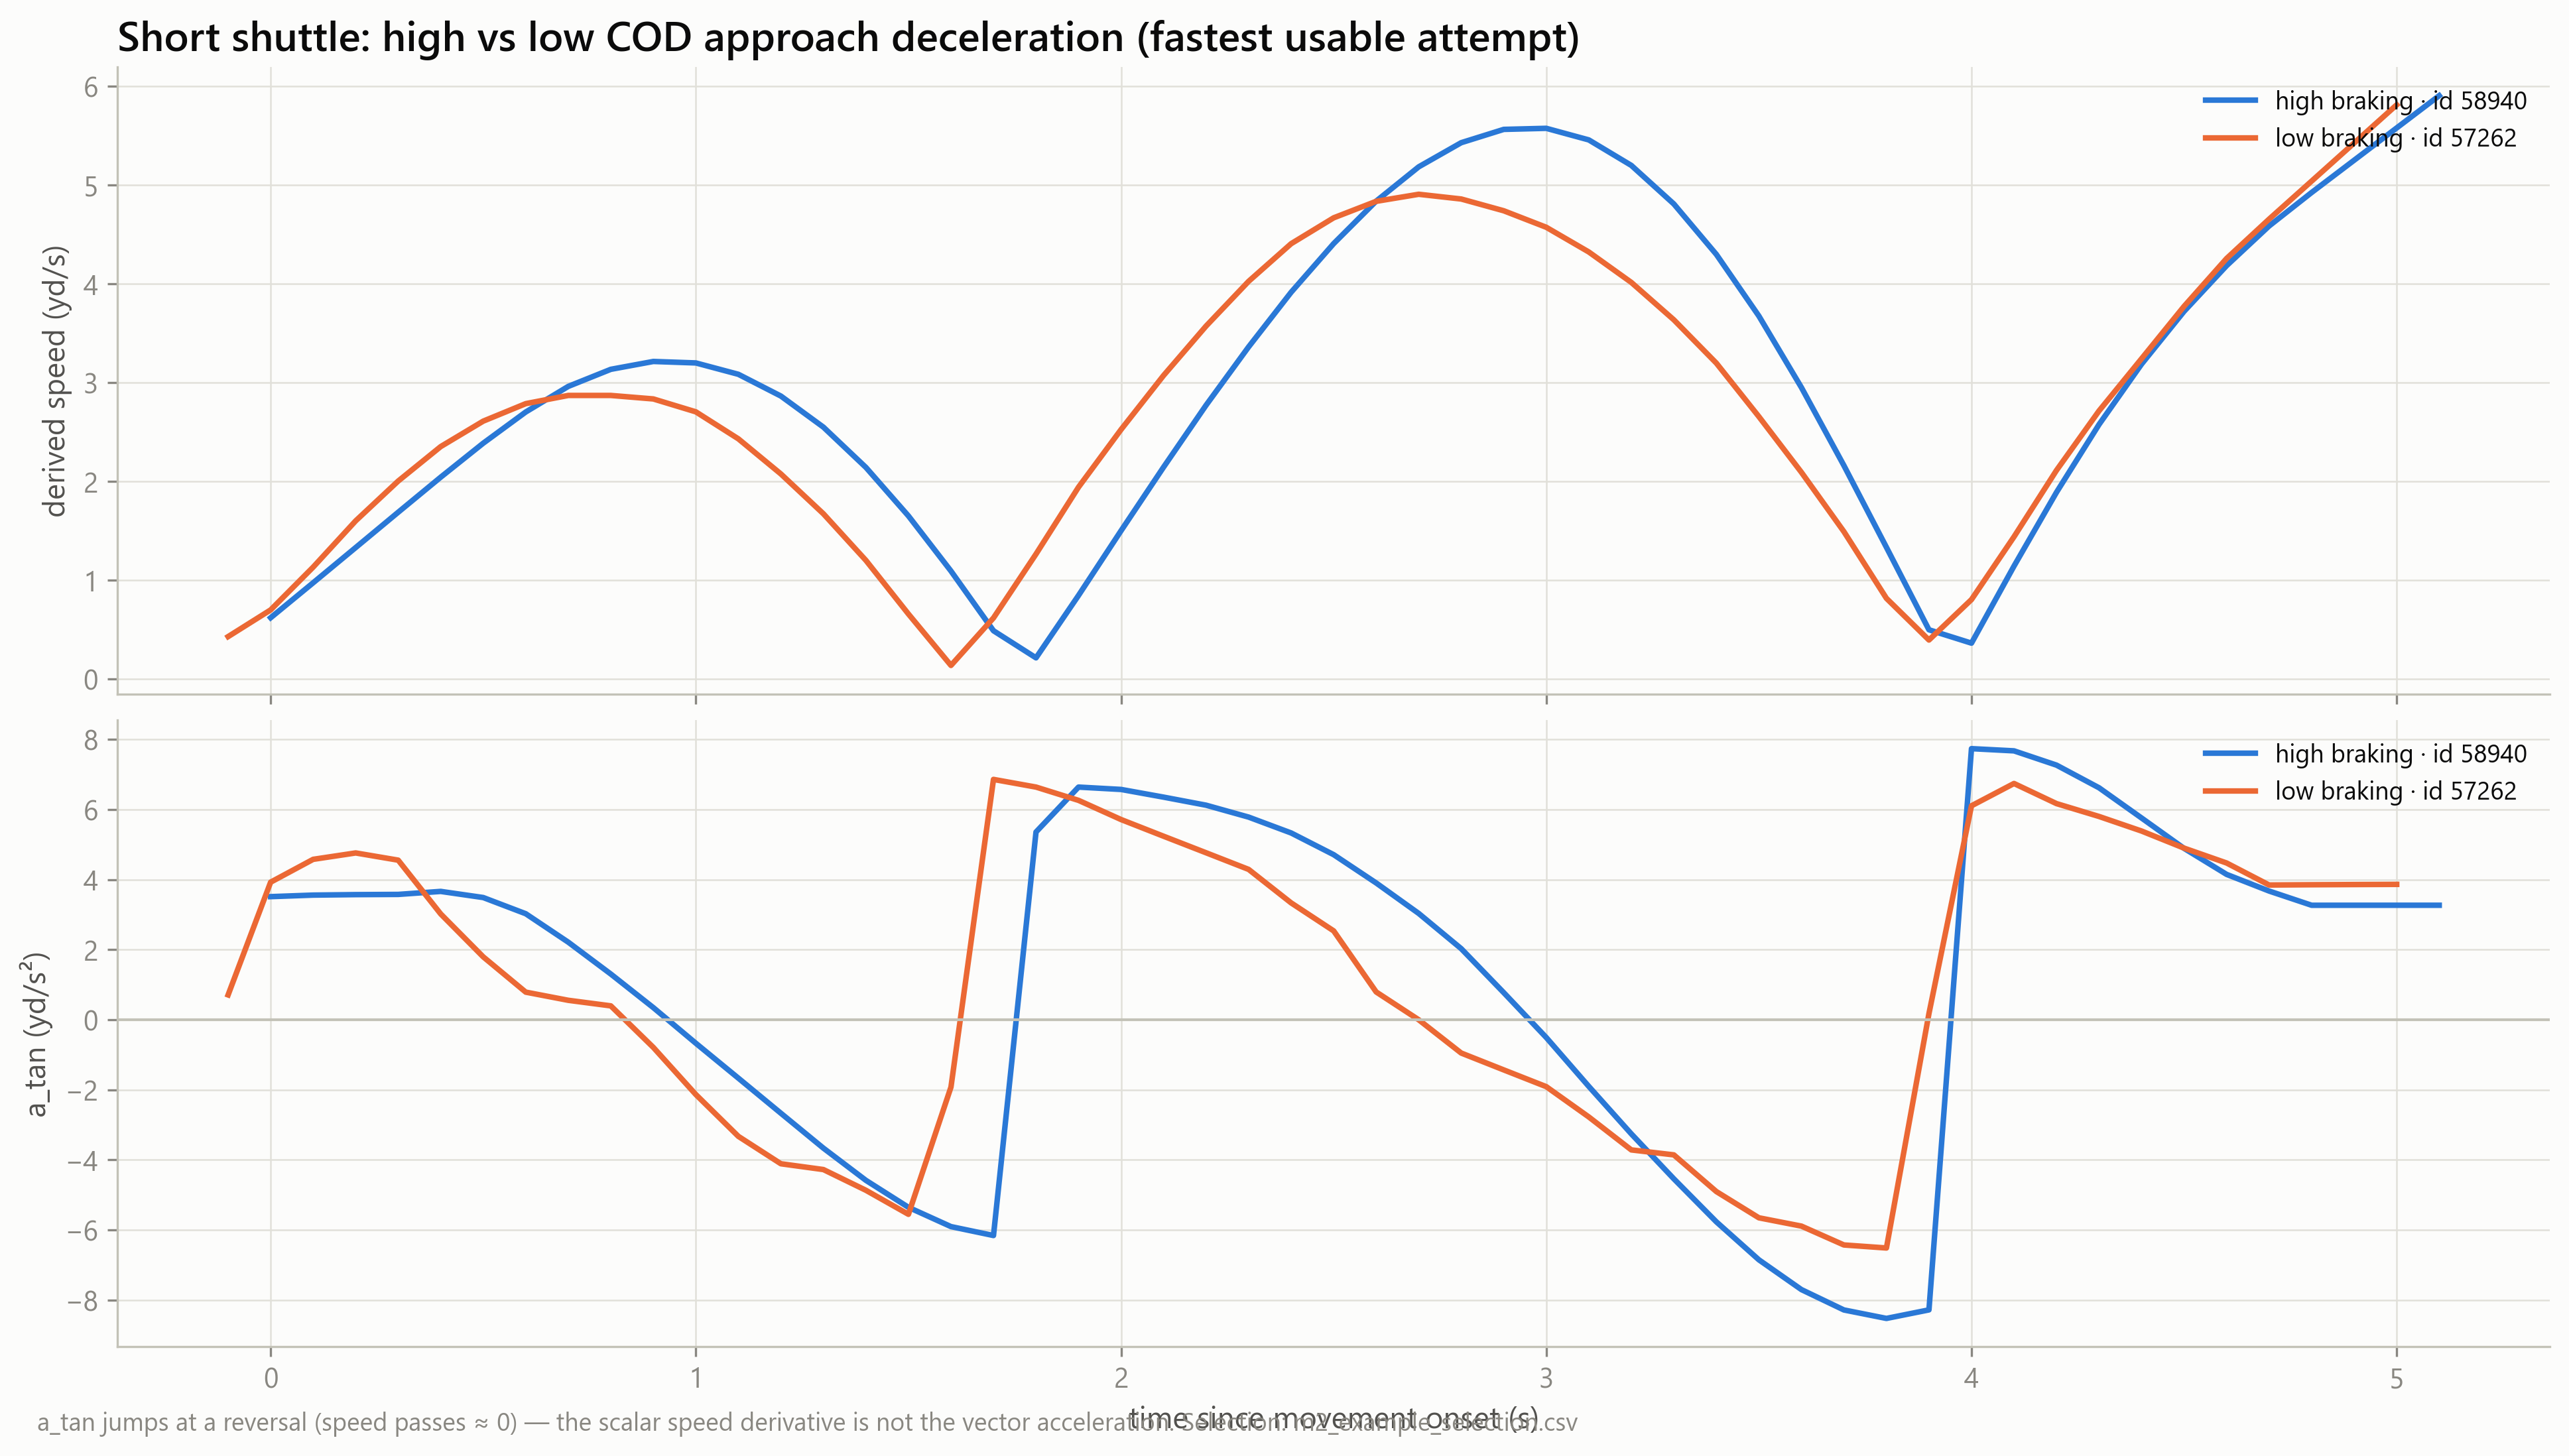

m2_sprint_model_quality.png


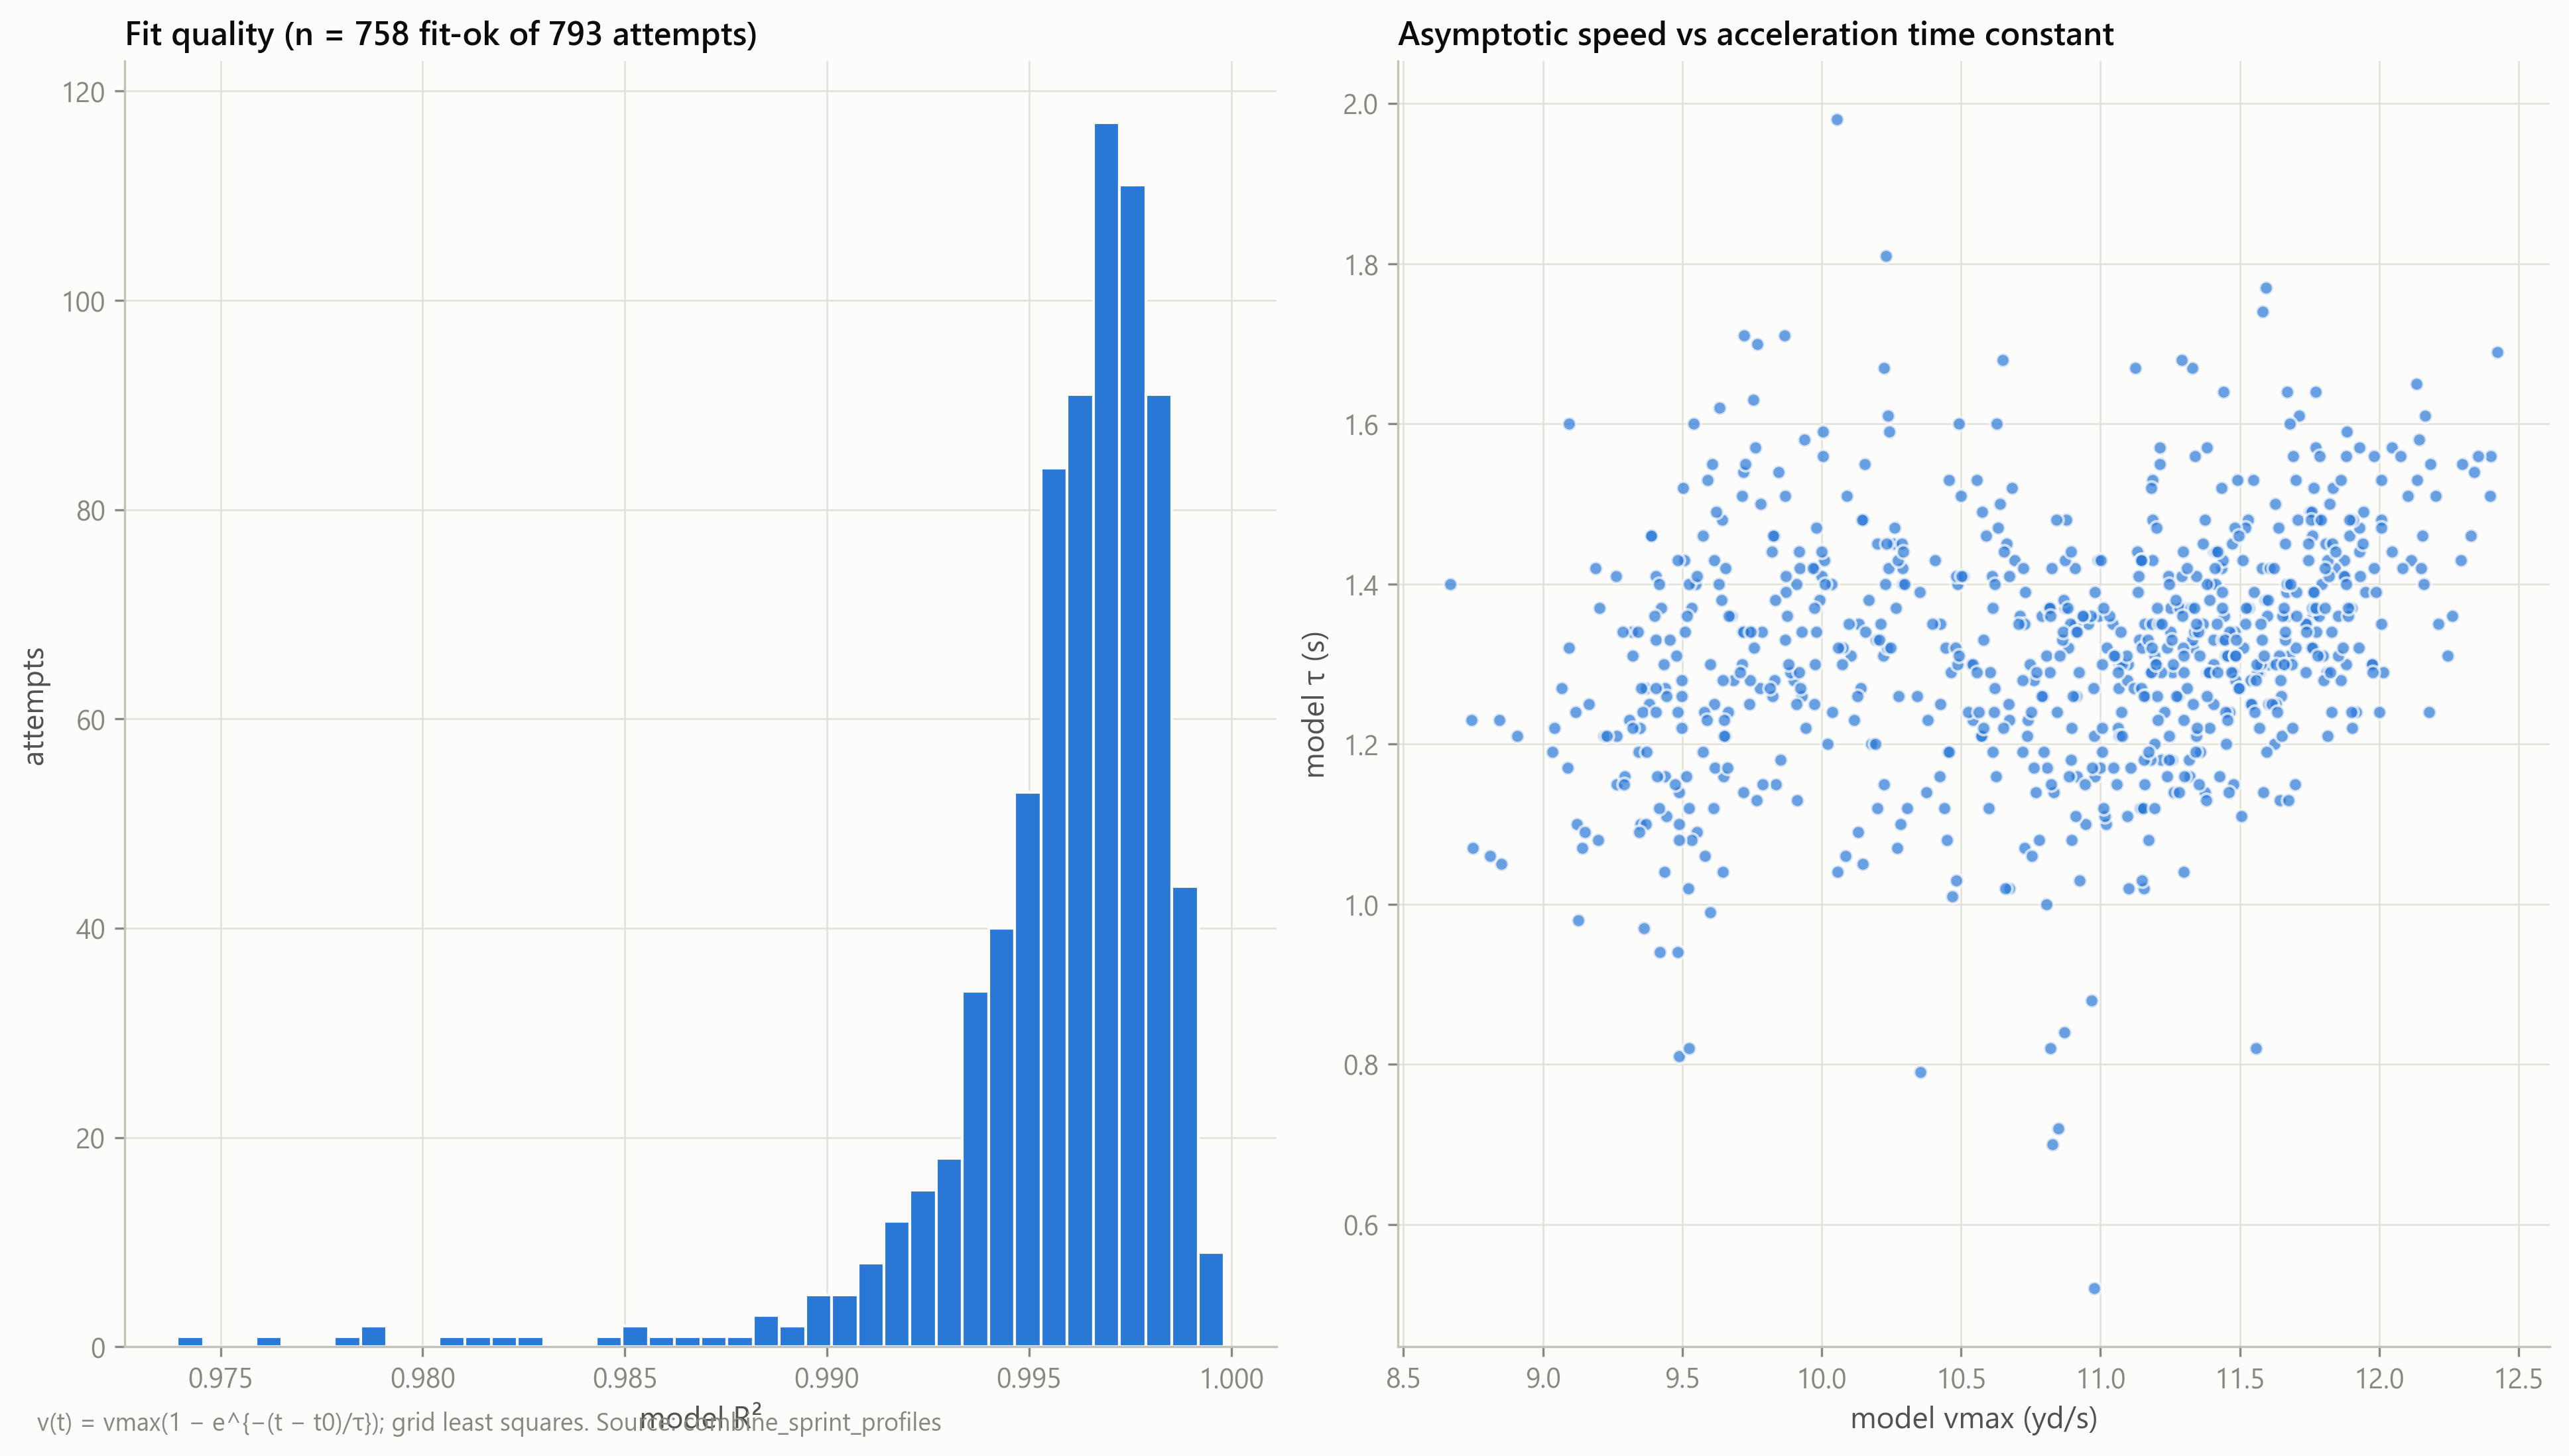

In [6]:
from IPython.display import Image, display
for p in sorted(store.figures_dir.glob('m2_*.png')):
    print(p.name); display(Image(filename=str(p), width=900))

## 8. Parquet persistence
`warehouse/gold/phase_03/combine_{attempt_features,cod_events,sprint_profiles,athlete_drill_features}.parquet` (+ `*.schema.json`, manifest). Reuse requires the M2 version, all `MovementConfig` + `KinematicsConfig` parameters and the upstream M1 file fingerprints to match.

## 9. Interpretation (fill in ONLY from executed outputs)
* Is the forty recording the timed run? (`forty_window_diagnostics`: run distance ≈ 40 yd? share onset-censored? share peak-at-end?) _…_
* Tracked vs official forty / 10-yd split — bias and correlation per cohort; which tracked convention agrees best? _…_  **Only if agreement is high may tracked splits be called split estimates.**
* Shuttle / three-cone — does `fast_onset_to_end_s` track the official time? Do COD counts match drill design (shuttle: 2 reversals)? _…_
* Similar official forty, different τ — size of the difference relative to attempt-to-attempt noise (see notebook 06) _…_
* Cohort shifts flagged (2025 has ~¼ the positional noise of 2023/24 per M1) — which features? _…_
* Redundant feature pairs (|ρ| ≥ 0.9) to drop before modelling _…_

## 10. Limitations
* Model-start / onset conventions are not the official timing convention; splits are not official splits.
* The mono-exponential model under-fits the first steps from a stance; `model_a0` is a model quantity, not a measured peak, and implies no force/power.
* Shuttle / three-cone recordings may include pre-start drift — hence two onset definitions.
* Position-drill features are drill-specific; comparisons across drills are not meaningful.
* Coordinate handedness unverified → turn sense unused.

## 11. Next analysis
Notebook 06 (attempt reliability) → choose reliable features; then M3 (NFL player-play features with play context).